# **Simulation and Characterization of Multilayer Optical Spaceplates Using Tidy3D ➿**


**Authors:** *Lucie Wang, Yaryna Mamchur, Manuel F. Ferrer-Garcia, Jeff S. Lundeen*

**Affiliation:** *Nexus for Quantum Technologies, Department of Physics, University of Ottawa, Ottawa, Ontario K1N 6N5, Canada*

This notebook demonstrates how to model and characterize multilayer optical spaceplates using the finite-difference time-domain (FDTD) method implemented in Tidy3D. We investigate the multilayer designs reported in [Ref. 1](#References) and numerically characterize their spectral and angular responses.

The workflow includes:

1. Define the optical materials and multilayer device parameters.
2. Generate and visualize multilayer geometries.
3. Construct FDTD simulations using plane-wave excitation.
4. Calculate wavelength-dependent transmittance and identify transmission resonances.
5. Visualize the electric-field distribution within the multilayer structures.
6. Calculate angle-dependent transmission amplitude and phase.
7. Extract the compression ratio and characterize the angular operating range.

The functions developed in this notebook provide a general framework for constructing and simulating multilayer optical structures with arbitrary layer thicknesses and material compositions.

Unless otherwise stated, all lengths are expressed in micrometers (µm).

## 1. Introduction to the Spaceplate

A **spaceplate** is an engineered optical element that reproduces the effect of free-space propagation within a much shorter physical distance. Rather than allowing a beam to accumulate phase over a long propagation path, a spaceplate applies an engineered angle-dependent transmission phase that mimmics the same transverse beam evolution as in free space. This allows an effective propagation distance, $d_{\text{eff}}$, to be reproduced using a device with a physical thickness, $d$, of only a few microns. The resulting compression ratio:

$$
R = \frac{d_{\text{eff}}}{d},
$$

can exceed one hundred in modern multilayer designs.

One approach to realizing a spaceplate is through multilayer dielectric structures composed of alternating high- and low-refractive-index materials. These multilayer stacks are designed to produce the required nonlocal phase response, enabling functions such as beam displacement, focal-plane shifting, and optical-system compression without changing image magnification. In this notebook, two multilayer design approaches are demonstrated: periodic structures based on Fabry–Pérot cavity (FPC) unit cells and aperiodic structures optimized using gradient-descent (GD) techniques.

Using Tidy3D, this notebook generates the multilayer geometries, constructs finite-difference time-domain (FDTD) simulations, visualizes the structures, and computes their wavelength-dependent transmission spectra to illustrate how multilayer design influences the optical response of spaceplates.

## **2. Necessary Imports**

### **Tested environment** ###

This notebook was developed and tested using:

- Python 3.11.15
- Tidy3D 2.11.2
- NumPy 2.4.6
- Matplotlib 3.11.0
- Pandas 3.0.3
- Scipy 1.17.1

The simulations require a Tidy3D account and API key to upload simulations to Tidy3D Cloud.

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
!pip install tidy3d
!pip install tidy3d-web

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 78.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.9/16.9 MB 143.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 785.9/785.9 kB 35.4 MB/s  0:00:00
  Attempting uninstall: importlib-metadata
    Found existing installation: importlib_metadata 10.1.0
    Uninstalling importlib_metadata-10.1.0:
      Successfully uninstalled importlib_metadata-10.1.0
  Attempting uninstall: filelock
    Found existing installation: filelock 4.2.7
    Uninstalling filelock-4.2.7:
      Successfully uninstalled filelock-4.2.7
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29/29 [tidy3d]
ERROR: Could not find a version that satisfies the requirement tidy3d-web (from versions: none)
ERROR: No matching distribution found for tidy3d-web


In [5]:
import matplotlib.pylab as plt
import numpy as np
import tidy3d as td
import tidy3d.web as web
import pandas as pd
import os
import sys
import matplotlib
import numpy
import scipy
from scipy.signal import find_peaks
from google.colab import userdata
tidy_token = userdata.get('Tidy3D')

# Configure Tidy3D Web API key
# Insert your own API key here when running the notebook.
# This will allow you to upload simulations to Tidy3D Web and run them on the cloud,
# and use the flex credit system to pay for the simulations.

#web.configure("YOUR_API_KEY_HERE")
web.configure(tidy_token)

Configuration saved successfully.
License cache refreshed (0 cached file(s) removed; next local license check will fetch current entitlements).


### **Runtime environment** ###

Users can use this cell to check their computer/laptop's versions.

In [6]:
print("Python:", sys.version)
print("Tidy3D:", td.__version__)
print("NumPy:", numpy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Pandas:", pd.__version__)
print("Scipy:", scipy.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Tidy3D: 2.12.2
NumPy: 2.4.6
Matplotlib: 3.10.0
Pandas: 2.2.3
Scipy: 1.16.3


## **3. Design Parameters**
These values are the same for every device or simulation

In [7]:
# Low and high refractive indices for every simulation, the values are for the spaceplate
# examples, but can be changed to any other values for different simulations.

nL = 1.44
nH = 3.200

# finite transverse size of simulations (avoids periodic explosion issues),
# can be changed for different simulations, but should be large enough to avoid edge
# effects.

y_span = 6
z_span = 6

## **4. Spaceplate Simulation Functions**

In [8]:
def create_materials(n_low, n_high):
    """
    Create Tidy3D dielectric materials for low and high refractive index layers.

    Parameters
    ----------
    n_low : float
        Refractive index of the low-index material layer.

    n_high : float
        Refractive index of the high-index material layer.

    Returns
    -------
    tuple[td.Medium, td.Medium]
        A tuple containing:
        - low_medium: Tidy3D material with permittivity = n_low^2.
        - high_medium: Tidy3D material with permittivity = n_high^2.
    """

    return (
        td.Medium(permittivity=n_low**2),
        td.Medium(permittivity=n_high**2),
    )

In [9]:
def create_FPC_parameters(lambda0, lambda_min, lambda_max, num_cells, nL, nH, pattern):
    """
    Generate Tidy3D frequency parameters from FPC device specifications.

    Parameters
    ----------
    lambda0 : float
            Design wavelength (um).

    lambda_min : float
        Minimum wavelength (um).

    lambda_max : float
        Maximum wavelength (um).

    num_cells : int
        Number of unit cells in the FPC device.

    nL : float
        Refractive index of low index layer.

    nH : float
        Refractive index of high index layer.

    pattern : list
        List of tuples specifying the unit cell pattern. Each tuple contains a string
        ('L' or 'H') indicating the layer type (Low or High) and an integer indicating
        the number of repetitions of that layer type.

    Returns
    -------
    dict
        Dictionary containing FPC specific parameters.
    """

    # Convert wavelength range into frequency range
    #
    # Tidy3D uses frequency, not wavelength, internally.
    # frequency = c / wavelength

    freq_min = td.C_0 / lambda_max
    freq_max = td.C_0 / lambda_min
    freq0 = (freq_min + freq_max) / 2
    fwidth = freq_max - freq_min
    tL = float(lambda0 / (4 * nL)) # Thickness of low index layer (um)
    tH =float(lambda0 / (4 * nH)) # Thickness of high index layer (um)

    return {
        "lambda0": lambda0,
        "lambda_min": lambda_min,
        "lambda_max": lambda_max,
        "freq_min": freq_min,
        "freq_max": freq_max,
        "freq0": freq0,
        "fwidth": fwidth,
        "freq_range": td.FreqRange(
            freq0=freq0,
            fwidth=fwidth,
        ),
        "num_cells": num_cells,
        "tL": tL,
        "tH": tH,
        "pattern": pattern
    }

In [10]:
def create_GD_parameters(
    lambda_min,
    lambda_max,
    *,
    layers=None,
    spreadsheet=None,
    thickness_column="Thickness",
    sheet_name=0,
    unit_scale=1.0,
):
    """
    Create the parameters required for a GD spaceplate.

    Layer thicknesses can be provided either:

    1. Directly as a Python list:
        layers=[0.1, 0.2, 0.1]

    OR

    2. Imported from a CSV or Excel spreadsheet:
        spreadsheet="layers.xlsx"

    Parameters
    ----------
    lambda_min : float
        Minimum wavelength (µm).

    lambda_max : float
        Maximum wavelength (µm).

    layers : list[float], optional
        Manually entered layer thicknesses.

    spreadsheet : str, optional
        Path to CSV or Excel file containing layer thicknesses.

    thickness_column : str or int
        Column containing thickness values.

    sheet_name : str or int
        CSV or Excel sheet to read.

    unit_scale : float
        Multiplier to convert units.
        Example:
            nm -> µm:
            unit_scale = 1e-3

    Returns
    -------
    dict
        Dictionary containing GD specific parameters.
    """
    # -------------------------------------------------------
    # STEP 1:
    # Obtain layer thicknesses
    #
    # We allow either:
    # - manually entered layers
    # - imported spreadsheet layers
    # -------------------------------------------------------
    if layers is not None and spreadsheet is not None:
        raise ValueError(
            "Provide either 'layers' or 'spreadsheet', not both."
        )

    # -------------------------------------------------------
    # Case 1:
    # User provides layers manually
    # -------------------------------------------------------
    if layers is not None:
        try:
            layers = [
                float(layer) * unit_scale
                for layer in layers
            ]
        except ValueError:
            raise ValueError(
                "Manual layers must contain only numerical values."
            )

    # -------------------------------------------------------
    # Case 2:
    # User provides spreadsheet
    # -------------------------------------------------------
    elif spreadsheet is not None:
        # Get file extension
        extension = os.path.splitext(spreadsheet)[1].lower()

        # Read CSV file
        if extension == ".csv":
            df = pd.read_csv(spreadsheet)

        # Read Excel file
        elif extension in [".xlsx", ".xls"]:
            df = pd.read_excel(
                spreadsheet,
                sheet_name=sheet_name,
            )
        else:
            raise ValueError(
                "Supported file formats are .csv, .xlsx and .xls."
            )

        # ---------------------------------------------------
        # Select the thickness column
        # ---------------------------------------------------
        if isinstance(thickness_column, str):
            # Check if column name exists  (if chosen to select column by name)
            if thickness_column not in df.columns:
                raise ValueError(
                    f"Column '{thickness_column}' was not found.\n"
                    f"Available columns: {list(df.columns)}"
                )
            layer_series = df[thickness_column]
        elif isinstance(thickness_column, int):
            # Select column by index
            layer_series = df.iloc[:, thickness_column]
        else:
            raise TypeError(
                "'thickness_column' must be a string "
                "or integer."
            )

        # ---------------------------------------------------
        # Convert thickness values into a Python list
        # ---------------------------------------------------
        try:
            layers = (
                layer_series
                .dropna()       # Remove empty spreadsheet rows
                .astype(float)  # Convert values to numbers
                * unit_scale
            ).tolist()


        except ValueError:
            raise ValueError(
                "The selected column contains non-numeric values."
            )

    # -------------------------------------------------------
    # If neither layers nor spreadsheet were provided
    # -------------------------------------------------------
    else:
        raise ValueError(
            "You must provide either 'layers' or 'spreadsheet'."
        )
    freq_min = td.C_0 / lambda_max
    freq_max = td.C_0 / lambda_min
    freq0 = (freq_min + freq_max) / 2
    fwidth = (freq_max - freq_min)

    return {
        "lambda_min": lambda_min,
        "lambda_max": lambda_max,
        "freq_min": freq_min,
        "freq_max": freq_max,
        "freq0": freq0,
        "fwidth": fwidth,
        "freq_range": td.FreqRange(
            freq0=freq0,
            fwidth=fwidth,
        ),
        "layers": layers,
    }

In [11]:
def generate_FPC_spaceplate(
        num_cells,
        pattern,
        tL,
        tH,
        low_medium,
        high_medium,
        y_span,
        z_span):

    """
    Generate the multilayer geometry of an FPC-based spaceplate.

    The function creates a list of Tidy3D structures by repeating a defined
    unit-cell pattern of low-index (L) and high-index (H) layers along the
    propagation direction (x-axis).

    Parameters
    ----------
    num_cells : int
        Number of times the unit-cell pattern is repeated.

    pattern : list[tuple]
        Layer sequence defining the unit cell.
        Each tuple contains:
        - "L" or "H" specifying low/high index material.
        - Integer multiplier specifying the number of repeated quarter-wave
        layers.

        Example:
            [("L", 2), ("H", 1)]

    tL : float
        Thickness of a single low-index layer (µm).

    tH : float
        Thickness of a single high-index layer (µm).

    low_medium : td.Medium
        Tidy3D material assigned to low-index layers.

    high_medium : td.Medium
        Tidy3D material assigned to high-index layers.

    y_span : float
        Width of each layer along the y-axis (µm).

    z_span : float
        Width of each layer along the z-axis (µm).

    Returns
    -------
    list[td.Structure]
        List of Tidy3D structures representing the complete multilayer
        FPC spaceplate geometry.
    """

    structures = []

    # Helper function to get the thickness and medium for a given layer type and multiplier.
    def get_layer(layer_type, multiplier):

        if layer_type == "L":
            thickness = multiplier * tL
            medium = low_medium
        elif layer_type == "H":
            thickness = multiplier * tH
            medium = high_medium
        else:
            raise ValueError(f"Unknown layer type '{layer_type}'")
        return thickness, medium

    # Create the first layer separately so it is not duplicated when
    # repeating the unit-cell pattern.
    layer_type, multiplier = pattern[0]
    first_thickness, first_medium = get_layer(layer_type, multiplier)

    structures.append(
        td.Structure(
            geometry=td.Box(
                center=(0, 0, 0),
                size=(first_thickness, y_span, z_span),
            ),
            medium=first_medium,
            name="Layer_1",
        )
    )

    # Track the previous layer so each new layer can be placed immediately
    # adjacent to it along the x-axis.
    previous_center = 0
    previous_thickness = first_thickness
    layer_number = 1

    # Repeat the unit-cell pattern.
    for cell in range(num_cells):

        # Skip the first layer of the pattern for the first cell since it
        # has already been created above.
        start = 1 if cell == 0 else 0

        for layer_type, multiplier in pattern[start:]:

            thickness, medium = get_layer(layer_type, multiplier)
            layer_number += 1

            # Position the new layer by moving half the previous layer's
            # thickness plus half the current layer's thickness.
            center_x = (
                previous_center
                + previous_thickness / 2
                + thickness / 2
            )

            structures.append(
                td.Structure(
                    geometry=td.Box(
                        center=(center_x, 0, 0),
                        size=(thickness, y_span, z_span),
                    ),
                    medium=medium,
                    name=f"Layer_{layer_number}",
                )
            )

            # Update the placement reference for the next layer.
            previous_center = center_x
            previous_thickness = thickness

    return structures

In [12]:
def generate_GD_spaceplate(layers, y_span, z_span):

    """
    Generate the multilayer geometry of a gradient-descent (GD) spaceplate.

    The function creates a sequence of alternating high-index and low-index
    layers using optimized layer thicknesses obtained from a GD design.
    Each layer is positioned consecutively along the propagation direction
    (x-axis).

    Parameters
    ----------
    layers : list[float]
        List of layer thicknesses (µm) in the order they appear in the
        spaceplate. The first layer is assigned the high-index material,
        and subsequent layers alternate between high and low index materials.

    y_span : float
        Width of each layer along the y-axis (µm).

    z_span : float
        Width of each layer along the z-axis (µm).

    Returns
    -------
    list[td.Structure]
        List of Tidy3D structures representing the complete GD spaceplate
        multilayer geometry.
    """

    structures = []

    first_thickness = layers[0]
    first_thickness = abs(float(first_thickness))

    structures.append(
        td.Structure(
            geometry=td.Box(
                center=(0, 0, 0),
                size=(first_thickness, y_span, z_span),
            ),
            medium=high_medium,
            name="Layer_1",
        )
    )

    previous_center = 0
    previous_thickness = first_thickness
    layer_number = 1

    for thickness in layers[1:]:

            thickness = abs(float(thickness))

            layer_number += 1

            center_x = (
                previous_center
                + previous_thickness / 2
                + thickness / 2
            )

            if layer_number % 2 == 0:
                medium = low_medium
            else:
                medium = high_medium

            structures.append(
                td.Structure(
                    geometry=td.Box(
                        center=(center_x, 0, 0),
                        size=(thickness, y_span, z_span),
                    ),
                medium=medium,
                name=f"layer_{layer_number}",
            )
        )

            previous_center = center_x
            previous_thickness = thickness

    return structures

In [13]:
def visualize_structures(structures, sim_size, sim_center=(0,0,0)):
    """
    Create a Tidy3D simulation for visualizing the generated multilayer
    geometry before running an FDTD simulation.

    The simulation contains only the structures and the minimum settings
    required for plotting. No source or monitors are included.

    Parameters
    ----------
    structures : list[td.Structure]
        List of Tidy3D structures representing the multilayer geometry.

    sim_size : tuple(float, float, float)
        Size of the visualization region in microns:
        (x_size, y_size, z_size).

    sim_center : tuple(float, float, float), optional
        Center of the visualization region in microns:
        (x, y, z).
        Default is (0, 0, 0).

    Returns
    -------
    td.Simulation
        A Tidy3D simulation object that can be visualized using
        `sim.plot(z=0)` to verify the generated geometry.
    """

    sim = td.Simulation(

        # Center and size of the visualization region
        center=sim_center,
        size=sim_size,

        # Minimal grid only for visualization
        grid_spec=td.GridSpec.auto(
            wavelength=1.55,
            min_steps_per_wvl=10,
        ),

        # Add generated multilayer structures
        structures=structures,

        # Very short runtime because we will not run it
        run_time=1e-12,

        # Boundary conditions do not matter much here,
        # but they are required by Tidy3D
        boundary_spec=td.BoundarySpec(
            x=td.Boundary.pml(),
            y=td.Boundary.periodic(),
            z=td.Boundary.periodic(),
        ),
    )

    return sim

In [14]:
def build_spaceplate_transmission_simulation(
    structures,
    device_params,
    run_time,
    grid_steps,
    sim_size,
    monitor_points,
    source_center,
    monitor_center,
    monitor_size,
    sim_center,
    angle_theta=0.0,
    angle_phi=0.0
):
    """
    Build a Tidy3D FDTD simulation for evaluating the transmission of a
    multilayer spaceplate.

    Parameters
    ----------
    structures : list[td.Structure]
        Multilayer geometry of the spaceplate.

    device_params : dict
        Dictionary returned by create_FPC_parameters() or
        create_GD_parameters(), containing the wavelength and frequency
        parameters required for the simulation.

    run_time : float
        Simulation runtime (s).

    grid_steps : int
        Number of grid cells per wavelength used for automatic mesh
        generation.

    sim_size : tuple(float, float, float)
        Simulation domain size (µm).

    monitor_points : int
        Number of frequency points sampled by the transmission monitor.

    source_center : tuple(float, float, float)
        Position of the plane-wave source (µm).

    monitor_center : tuple(float, float, float)
        Position of the transmission monitor (µm).

    monitor_size : tuple(float, float, float)
        Size of the transmission monitor (µm).

    sim_center : tuple(float, float, float)
        Center of the simulation domain (µm).

    Returns
    -------
    td.Simulation
        Configured Tidy3D simulation object containing the spaceplate,
        broadband source, transmission monitor, and simulation settings.
    """

    source = td.PlaneWave(
        center=source_center,
        size=(0, td.inf, td.inf),
        source_time=td.GaussianPulse(
            freq0=device_params["freq0"],
            fwidth=device_params["fwidth"],
        ),
        direction="+",
        angle_theta=angle_theta,
        angle_phi=angle_phi,
        pol_angle=0,
        angular_spec=td.FixedAngleSpec(),
    )


    monitor = td.FluxMonitor(
        center=monitor_center,
        size=monitor_size,
        freqs=device_params["freq_range"].freqs(
            num_points=monitor_points
        ),
        name="transmission_monitor",
    )


    return td.Simulation(
        center=sim_center,
        size=sim_size,

        grid_spec=td.GridSpec.auto(
            wavelength=device_params["lambda_min"],
            min_steps_per_wvl=grid_steps,
        ),

        structures=structures,
        sources=[source],
        monitors=[monitor],

        run_time=run_time,

        boundary_spec=td.BoundarySpec(
            x=td.Boundary.pml(),
            y=td.Boundary.periodic(),
            z=td.Boundary.periodic(),
        ),
    )

In [15]:
def build_spaceplate_field_simulation(
    structures,
    device_params,
    run_time,
    grid_steps,
    sim_size,
    field_monitor_points,
    source_center,
    field_monitor_center,
    field_monitor_size,
    sim_center
):
    """
    Build a Tidy3D FDTD simulation for evaluating the electric
    field distribution of a multilayer spaceplate.

    Parameters
    ----------
    structures : list[td.Structure]
        Multilayer geometry of the spaceplate.

    device_params : dict
        Dictionary returned by create_FPC_parameters()
        or create_GD_parameters().

    run_time : float
        Simulation runtime (s).

    grid_steps : int
        Number of grid cells per wavelength.

    sim_size : tuple(float, float, float)
        Simulation domain size (µm).

    field_monitor_points : int
        Number of frequency points sampled by the field monitor.

    source_center : tuple(float, float, float)
        Position of the plane-wave source (µm).

    field_monitor_center : tuple(float, float, float)
        Position of the field monitor (µm).

    field_monitor_size : tuple(float, float, float)
        Size of the field monitor (µm).

    sim_center : tuple(float, float, float)
        Center of the simulation domain (µm).

    Returns
    -------
    td.Simulation
        Configured Tidy3D FDTD simulation containing the
        spaceplate, source, and field monitor.
    """

    source = td.PlaneWave(
        center=source_center,
        size=(0, td.inf, td.inf),
        source_time=td.GaussianPulse(
            freq0=device_params["freq0"],
            fwidth=device_params["fwidth"],
        ),
        direction="+",
    )

    field_monitor = td.FieldMonitor(
        center=field_monitor_center,
        size=field_monitor_size,
        freqs=device_params["freq_range"].freqs(
            num_points=field_monitor_points
        ),
        fields=["Ex", "Ey", "Ez"],
        name="field_monitor",
    )

    return td.Simulation(
        center=sim_center,
        size=sim_size,
        grid_spec=td.GridSpec.auto(
            wavelength=device_params["lambda_min"],
            min_steps_per_wvl=grid_steps,
        ),
        structures=structures,
        sources=[source],
        monitors=[field_monitor],
        run_time=run_time,
        boundary_spec=td.BoundarySpec(
            x=td.Boundary.pml(),
            y=td.Boundary.periodic(),
            z=td.Boundary.periodic(),
        ),
    )

In [ ]:
# ============================================================
# DEVICE THICKNESS
# ============================================================

def get_device_thickness(structures):
    """
    Calculate the physical thickness of a multilayer spaceplate
    along the propagation direction x.
    """

    x_start, x_end = get_spaceplate_extent(
        structures
    )

    return float(
        x_end - x_start
    )


# Calculate thickness for all devices

d_FPC1 = get_device_thickness(
    spaceplate_FPC1
)

d_FPC2 = get_device_thickness(
    spaceplate_FPC2
)

d_GD1 = get_device_thickness(
    spaceplate_GD1
)

d_GD2 = get_device_thickness(
    spaceplate_GD2
)


print(
    f"FPC1 thickness = {d_FPC1:.6f} µm"
)

print(
    f"FPC2 thickness = {d_FPC2:.6f} µm"
)

print(
    f"GD1 thickness  = {d_GD1:.6f} µm"
)

print(
    f"GD2 thickness  = {d_GD2:.6f} µm"
)

## **5. Example Devices**

In [16]:
#  Create Tidy3D materials for low and high index layers using the specified refractive
# indices. This is run once here as it applies to all spaceplate devices, but can be
# changed for different simulations, as needed.

low_medium, high_medium = create_materials(
    n_low=nL,
    n_high=nH
)

### FPC1 Parameters

In [17]:
FPC1 = create_FPC_parameters(
    lambda0=1.54368,
    lambda_min=1.450,
    lambda_max=1.600,
    num_cells=8,
    nL=nL,
    nH=nH,
    # FPC1 device unit cell multilayer pattern (low and high refractive index layers):
    # 2L, H, 3L, H
    # where:
    # L = low index quarter-wave layer, H = high index quarter-wave layer
    pattern = [
        ("L", 2),
        ("H", 1),
        ("L", 3),
        ("H", 1),
    ]
)

### FPC2 Parameters

In [18]:
FPC2 = create_FPC_parameters(
    lambda0=1.5468836,
    lambda_min=1.52,
    lambda_max=1.57,
    num_cells=4,
    nL=nL,
    nH=nH,
    pattern = [
        ("L", 2),
        ("H", 1),
        ("L", 3),
        ("H", 1),
        ("L", 1),
        ("H", 1),
        ("L", 3),
        ("H", 1)
    ]
)

### GD1 Parameters (Example for manual input layer thicknesses)

In [21]:
GD1 = create_GD_parameters(
    lambda_min = 1.500,
    lambda_max = 1.580,
    # GD1 manually inputted device layer thicknesses, in order (um)
    layers = [
        0.1189, 0.1959,
        0.1355, 0.1942,
        0.1313, 0.1912,
        0.1159, 0.1107,
        0.0961, 0.1278,
        0.1233, 0.1753,
        0.1339, 0.1880,
        0.1370, 0.1897,
        0.1186
    ]
)

### GD2 Parameters (Example for csv imported layer thicknesses)

In [20]:
GD2 = create_GD_parameters(
    lambda_min = 1.500,
    lambda_max = 1.580,
    spreadsheet =  "/content/drive/Shareddrives/Lundeen Lab/Projects/Optical elements on spaceplates/Tidy3D library/GD2_layers.csv",
    thickness_column = "Layer Thicknesses",
    unit_scale=1 # data was already in microns
)


# Commented out layer values for reference:
#layers = [
#        0.1227,0.2668,0.3872,0.3844,0.1438,
#        0.2343,0.2940,0.2958,0.2250,0.1530,
#        0.2290,0.2034,0.3430,0.4079,0.3720,
#        0.2599,0.2050,0.2748,l0.3353,0.3690,
#        0.3170,0.2705,0.2860,0.3362,0.2580,
#        0.2792,0.3490,0.1442,0.2740,0.4035,
#        0.2060,0.2497,0.3440,0.2783,0.2660,
#        0.3810,0.1640,0.3076,0.1610,0.1805,
#        0.2080,0.3898,0.2985,0.1962,0.2233,
#        0.3029,0.2800,0.2044,0.3535
#    ]

## **6. Generation of multilayer geometries for each device**

In [22]:
# FPC devices
spaceplate_FPC1 = generate_FPC_spaceplate(
    FPC1["num_cells"],
    FPC1["pattern"],
    FPC1["tL"],
    FPC1["tH"],
    low_medium,
    high_medium,
    y_span,
    z_span)

spaceplate_FPC2 = generate_FPC_spaceplate(
    FPC2["num_cells"],
    FPC2["pattern"],
    FPC2["tL"],
    FPC2["tH"],
    low_medium,
    high_medium,
    y_span,
    z_span)

# GD devices
spaceplate_GD1 = generate_GD_spaceplate(
    GD1["layers"],
    y_span,
    z_span)

spaceplate_GD2 = generate_GD_spaceplate(
    GD2["layers"],
    y_span,
    z_span)

## **7. Visualize structures**

<Axes: title={'center': 'cross section at z=0.00 (μm)'}, xlabel='x (μm)', ylabel='y (μm)'>

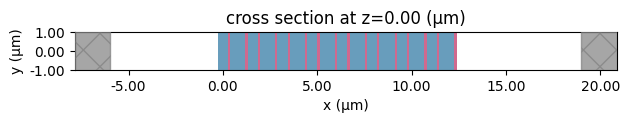

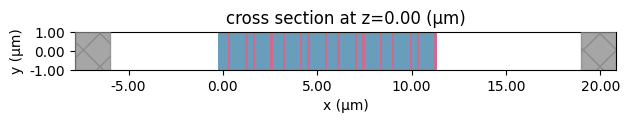

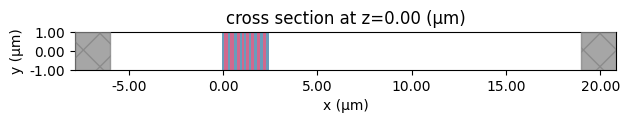

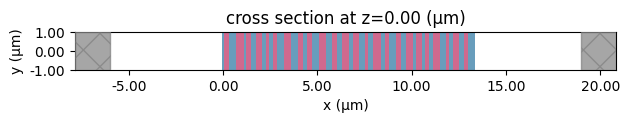

In [23]:
vis_FPC1 = visualize_structures(
    spaceplate_FPC1,
    sim_size=(25,2,0),
    sim_center=(6.5,0,0)
)

vis_FPC2 = visualize_structures(
    spaceplate_FPC2,
    sim_size=(25,2,0),
    sim_center=(6.5,0,0)
)

vis_GD1 = visualize_structures(
    spaceplate_GD1,
    sim_size=(25,2,0),
    sim_center=(6.5,0,0)
)

vis_GD2 = visualize_structures(
    spaceplate_GD2,
    sim_size=(25,2,0),
    sim_center=(6.5,0,0)
)


vis_FPC1.plot(z=0)
vis_FPC2.plot(z=0)
vis_GD1.plot(z=0)
vis_GD2.plot(z=0)

## **8. Simulation Build and visualizations**

This section constructs the **Tidy3D FDTD simulation** used to evaluate the optical response of the multilayer spaceplate.

The simulation consists of:

- a **source** to excite the structure,
- **monitors** to measure the electromagnetic response,
- the **spaceplate geometry**,
- and the numerical settings controlling the FDTD solver.

---

### Source

The source defines the incident electromagnetic field entering the simulation.

We illuminate the spaceplate with a broadband plane-wave source at normal incidence. The source is defined by a Gaussian temporal pulse with a bandwidth chosen to cover the wavelength range of interest, from $\lambda_{min}$ to $\lambda_{max}$. This allows the spectral response of the structure to be calculated from a single FDTD simulation.

The incident plane wave propagates along the positive $x$ direction, corresponding to propagation from left to right in the simulation visualizations. The incident field is linearly polarized ($p$).

Important considerations:

- The source should be positioned before the structure along the propagation direction.
- The polarization and propagation direction must match the intended excitation conditions.
- The source bandwidth determines the frequency range over which the response is calculated.


---

### Monitors

Monitors record electromagnetic quantities during the simulation without affecting the fields.

We perform two types of simulations to characterize the spaceplates: spectral transmission simulations and spatial field-distribution simulations.


For the transmission simulations, a flux monitor is placed after the spaceplate to record the transmitted electromagnetic power as a function of frequency.

For the spatial field-distribution simulations, a field monitor records the complex electric-field components across a longitudinal cross-section of the spaceplate.

Additional monitors can be added to measure other quantities.


---

### Simulation Domain and FDTD Grid

The FDTD solver discretizes the simulation domain into a spatial grid and updates the electromagnetic fields over time. The simulation parameters for each device are specified in the following subsections.

Since the multilayer structures are translationally invariant along the transverse directions, the plane-wave response considered here can be calculated using a two-dimensional simulation in the $x$-$y$ plane, assuming invariance along the $z$ direction.

Important considerations:

- **Grid resolution:** Determines how accurately material interfaces, geometric features, and electromagnetic phase accumulation are represented. A finer grid generally improves numerical accuracy but increases computational cost.
- **Simulation time:** Must be long enough for the fields to propagate through the structure and for the frequency-domain response to converge.

---

### Boundary Conditions

Boundary conditions define how electromagnetic fields behave at the edges of the simulation domain. For our system we used:

- **Perfectly matched layers (PML)**: Applied along the $x$ direction to absorb outgoing electromagnetic waves and minimize artificial reflections from the computational boundaries.
- **Periodic boundaries**: Applied along the $y$ direction to represent a laterally extended multilayer structure under plane-wave illumination at normal incidence.

The boundary conditions should always match the physical system being modeled.

---

### Geometry Verification

Before running simulations, visualize the setup to confirm that:

- The source is positioned before the structure along the propagation direction
- The monitor measures the desired output
- The geometry is oriented correctly
- The simulation domain is large enough to avoid boundary artifacts

---

### Notes for Future Modifications

When modifying the simulation, verify that:

- The grid resolution is sufficient to resolve the shortest wavelength within the materials and the smallest geometric features
- The simulation time is sufficient for the frequency-domain response to converge
- the boundary conditions still represent the intended physical system,
- the source and monitor placement remain appropriate.

For highly resonant or phase-sensitive structures (such as GD2), changes to the grid resolution or simulation time can modify transmission peak positions and amplitudes. Small changes in grid resolution may alter how interfaces are discretized ("snapped") onto the FDTD grid, leading to slightly different effective geometries and optical responses.

### FPC 1 Simulation

<Axes: title={'center': 'cross section at z=0.00 (μm)'}, xlabel='x (μm)', ylabel='y (μm)'>

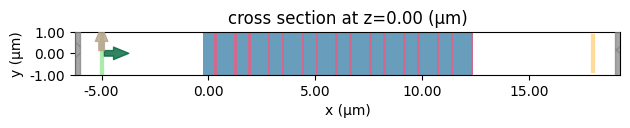

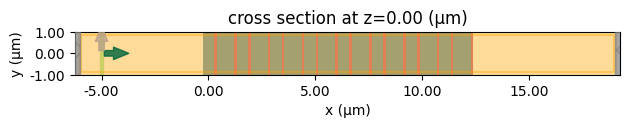

In [24]:
# Build transmission and field simulations

sim_FPC1_transmission = build_spaceplate_transmission_simulation(
    structures=spaceplate_FPC1,
    device_params=FPC1,
    run_time=8e-12,
    grid_steps=70,
    sim_size=(25,2,0),
    monitor_points=1500,
    source_center=(-5,0,0),
    monitor_center=(18,0,0),
    monitor_size=(0,1.8,1.8),
    sim_center=(6.5,0,0)
)

sim_FPC1_field = build_spaceplate_field_simulation(
    structures=spaceplate_FPC1,
    device_params=FPC1,
    run_time=8e-12,
    grid_steps=70,
    sim_size=(25, 2, 0),
    field_monitor_points=100,
    source_center=(-5, 0, 0),
    field_monitor_center=(6.5, 0, 0),
    field_monitor_size=(25, 1.8, 0),
    sim_center=(6.5, 0, 0)
)

# visualize
sim_FPC1_transmission.plot(z=0)

# visualize
sim_FPC1_field.plot(z=0)

### FPC 2 Simulation

<Axes: title={'center': 'cross section at z=0.00 (μm)'}, xlabel='x (μm)', ylabel='y (μm)'>

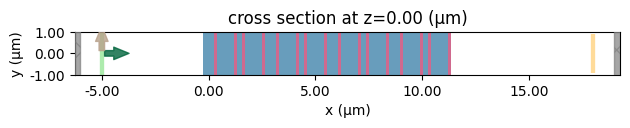

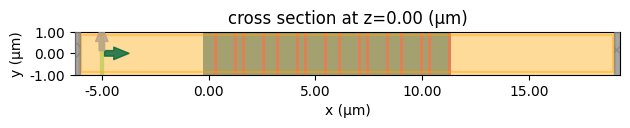

In [25]:
sim_FPC2_transmission = build_spaceplate_transmission_simulation(
    structures=spaceplate_FPC2,
    device_params=FPC2,
    run_time=2.5e-11,
    grid_steps=70,
    sim_size=(25,2,0),
    monitor_points=1500,
    source_center=(-5,0,0),
    monitor_center=(18,0,0),
    monitor_size=(0,1.8,1.8),
    sim_center=(6.5,0,0)
)

sim_FPC2_field = build_spaceplate_field_simulation(
    structures=spaceplate_FPC2,
    device_params=FPC2,
    run_time=2.5e-11,
    grid_steps=70,
    sim_size=(25,2,0),
    field_monitor_points=100,
    source_center=(-5,0,0),
    field_monitor_center=(6.5,0,0),
    field_monitor_size=(25,1.8,0),
    sim_center=(6.5,0,0)
)

sim_FPC2_transmission.plot(z=0)
sim_FPC2_field.plot(z=0)

### GD1 Simulation

<Axes: title={'center': 'cross section at z=0.00 (μm)'}, xlabel='x (μm)', ylabel='y (μm)'>

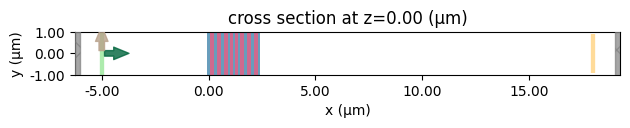

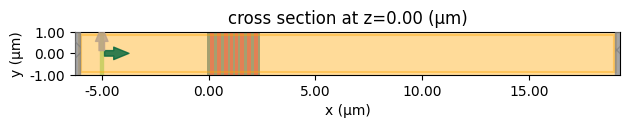

In [26]:
sim_GD1_transmission = build_spaceplate_transmission_simulation(
    structures=spaceplate_GD1,
    device_params=GD1,
    run_time=2e-11,
    grid_steps=70,
    sim_size=(25,2,0),
    monitor_points=1500,
    source_center=(-5,0,0),
    monitor_center=(18,0,0),
    monitor_size=(0,1.8,1.8),
    sim_center=(6.5,0,0)
)

sim_GD1_field = build_spaceplate_field_simulation(
    structures=spaceplate_GD1,
    device_params=GD1,
    run_time=2e-11,
    grid_steps=70,
    sim_size=(25,2,0),
    field_monitor_points=100,
    source_center=(-5,0,0),
    field_monitor_center=(6.5,0,0),
    field_monitor_size=(25,1.8,0),
    sim_center=(6.5,0,0)
)

# visualize
sim_GD1_transmission.plot(z=0)
sim_GD1_field.plot(z=0)

### GD2 Simulation

<Axes: title={'center': 'cross section at z=0.00 (μm)'}, xlabel='x (μm)', ylabel='y (μm)'>

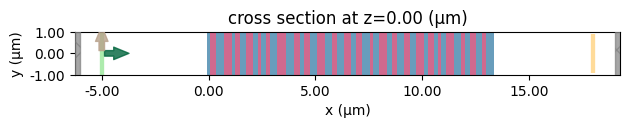

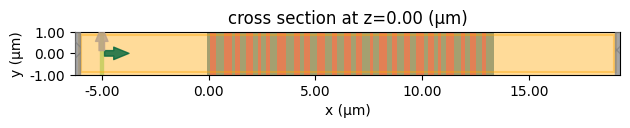

In [27]:
sim_GD2_transmission = build_spaceplate_transmission_simulation(
    structures=spaceplate_GD2,
    device_params=GD2,
    run_time=3e-11,
    grid_steps=70,
    sim_size=(25,2,0),
    monitor_points=1500,
    source_center=(-5,0,0),
    monitor_center=(18,0,0),
    monitor_size=(0,1.8,1.8),
    sim_center=(6.5,0,0)
)

sim_GD2_field = build_spaceplate_field_simulation(
    structures=spaceplate_GD2,
    device_params=GD2,
    run_time=3e-11,
    grid_steps=70,
    sim_size=(25,2,0),
    field_monitor_points=100,
    source_center=(-5,0,0),
    field_monitor_center=(6.5,0,0),
    field_monitor_size=(25,1.8,0),
    sim_center=(6.5,0,0)
)

# visualize
sim_GD2_transmission.plot(z=0)
sim_GD2_field.plot(z=0)

## **9. Uploading and Running simulations with Tidy3D**

There are two different workflows for submitting simulations to Tidy3D Cloud. Choose **one** method. For both methods, simulation files will appear in your Tidy3D web workspace in a new folder named "default".

### Option 1: Upload only, then manually run from Tidy3D Web

The simulation objects are uploaded to the Tidy3D workspace without immediately starting the solver.

This is useful for:
- inspecting the geometry,
- checking the estimated flex credit cost,
- verifying simulation settings before running.

After uploading, the simulation can be started manually from the Tidy3D Web interface.

### Option 2: Upload and run directly from Python

Using `web.run()` submits the simulation to Tidy3D Cloud and starts the solver immediately.

This is convenient for automated workflows, but the simulation will begin running without requiring manual confirmation of the estimated cost.

**Important:**
`web.run()` creates a new cloud task. It does not run an already uploaded task.

If a simulation has already been uploaded using `web.upload()`, it should be run manually from the Tidy3D Web interface.

### Notes:
- If a simulation is uploaded again after modifications, delete the previous cloud task or use a different task name to avoid confusion, sometimes the code may not run if the a task with the same name already exists on the cloud.
- Avoid mixing `web.upload()` and `web.run()` for the same simulation unless you intentionally want two separate cloud tasks.


In [ ]:
# CODE CELL FOR OPTION 1, uploading all Spaceplate devices

FPC1_transmission = web.upload(
    sim_FPC1_transmission,
    task_name="FPC1_Transmission_sim"
)

FPC1_field = web.upload(
    sim_FPC1_field,
    task_name="FPC1_Field_sim"
)

FPC2_transmission = web.upload(
    sim_FPC2_transmission,
    task_name="FPC2_Transmission_sim"
)

FPC2_field = web.upload(
    sim_FPC2_field,
    task_name="FPC2_Field_sim"
)

GD1_transmission = web.upload(
    sim_GD1_transmission,
    task_name="GD1_Transmission_sim"
)

GD1_field = web.upload(
    sim_GD1_field,
    task_name="GD1_Field_sim"
)



22:26:49 UTC Created task 'FPC1_Transmission_sim' with resource_id              
             'fdve-73c7effe-c452-45eb-995c-e1ef64fc2db3' and task_type 'FDTD'.

             View task using web UI at                                          
             ]8;id=182208;https://tidy3d.simulation.cloud/workbench?taskId=fdve-73c7effe-c452-45eb-995c-e1ef64fc2db3\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=987577;https://tidy3d.simulation.cloud/workbench?taskId=fdve-73c7effe-c452-45eb-995c-e1ef64fc2db3\taskId]8;;\]8;id=182208;https://tidy3d.simulation.cloud/workbench?taskId=fdve-73c7effe-c452-45eb-995c-e1ef64fc2db3\=]8;;\]8;id=381244;https://tidy3d.simulation.cloud/workbench?taskId=fdve-73c7effe-c452-45eb-995c-e1ef64fc2db3\fdve]8;;\]8;id=182208;https://tidy3d.simulation.cloud/workbench?taskId=fdve-73c7effe-c452-45eb-995c-e1ef64fc2db3\-73c7effe-c45]8;;\
             ]8;id=182208;https://tidy3d.simulation.cloud/workbench?taskId=fdve-73c7effe-c452-45eb-995c-e1ef64fc2db3\2-45eb-995c-e1ef64fc2db3']8;;\.

             Task folder: ]8;id=774;https://tidy3d.simulation.cloud/folders/folder-7b542f08-3da8-461c-9d93-ae083474555e\'default']8;;\.

Output()

22:26:50 UTC Estimated FlexCredit cost: 0.086. This assumes the FDTD solver runs
             for the full simulation time; if early shutoff is reached, the     
             billed cost can be lower. Use 'web.real_cost(task_id)' to get the  
             billed FlexCredit cost after a simulation run.

             Created task 'FPC1_Field_sim' with resource_id                     
             'fdve-df472df9-1284-4f84-b60f-f86c18c8afa7' and task_type 'FDTD'.

... (24 outputs left out)

             View task using web UI at                                          
             ]8;id=566182;https://tidy3d.simulation.cloud/workbench?taskId=fdve-df2e2e6f-99ab-4173-8ab9-1b6d9601c77b\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=537467;https://tidy3d.simulation.cloud/workbench?taskId=fdve-df2e2e6f-99ab-4173-8ab9-1b6d9601c77b\taskId]8;;\]8;id=566182;https://tidy3d.simulation.cloud/workbench?taskId=fdve-df2e2e6f-99ab-4173-8ab9-1b6d9601c77b\=]8;;\]8;id=593166;https://tidy3d.simulation.cloud/workbench?taskId=fdve-df2e2e6f-99ab-4173-8ab9-1b6d9601c77b\fdve]8;;\]8;id=566182;https://tidy3d.simulation.cloud/workbench?taskId=fdve-df2e2e6f-99ab-4173-8ab9-1b6d9601c77b\-df2e2e6f-99a]8;;\
             ]8;id=566182;https://tidy3d.simulation.cloud/workbench?taskId=fdve-df2e2e6f-99ab-4173-8ab9-1b6d9601c77b\b-4173-8ab9-1b6d9601c77b']8;;\.

             Task folder: ]8;id=691166;https://tidy3d.simulation.cloud/folders/folder-7b542f08-3da8-461c-9d93-ae083474555e\'default']8;;\.

Output()

22:26:57 UTC Estimated FlexCredit cost: 0.293. This assumes the FDTD solver runs
             for the full simulation time; if early shutoff is reached, the     
             billed cost can be lower. Use 'web.real_cost(task_id)' to get the  
             billed FlexCredit cost after a simulation run.

In [ ]:
GD2_transmission = web.upload(
    sim_GD2_transmission,
    task_name="GD2_Transmission_sim"
)

GD2_field = web.upload(
    sim_GD2_field,
    task_name="GD2_Field_sim"
)

18:29:38 UTC WARNING: Simulation has 1.96e+06 time steps. The 'run_time' may be 
             unnecessarily large, unless there are very long-lived resonances.  

             Created task 'GD2_Transmission_sim' with resource_id               
             'fdve-966eda28-b638-4e3a-9730-f8399856d5e7' and task_type 'FDTD'.

             View task using web UI at                                          
             ]8;id=704013;https://tidy3d.simulation.cloud/workbench?taskId=fdve-966eda28-b638-4e3a-9730-f8399856d5e7\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=756954;https://tidy3d.simulation.cloud/workbench?taskId=fdve-966eda28-b638-4e3a-9730-f8399856d5e7\taskId]8;;\]8;id=704013;https://tidy3d.simulation.cloud/workbench?taskId=fdve-966eda28-b638-4e3a-9730-f8399856d5e7\=]8;;\]8;id=218134;https://tidy3d.simulation.cloud/workbench?taskId=fdve-966eda28-b638-4e3a-9730-f8399856d5e7\fdve]8;;\]8;id=704013;https://tidy3d.simulation.cloud/workbench?taskId=fdve-966eda28-b638-4e3a-9730-f8399856d5e7\-966eda28-b63]8;;\
             ]8;id=704013;https://tidy3d.simulation.cloud/workbench?taskId=fdve-966eda28-b638-4e3a-9730-f8399856d5e7\8-4e3a-9730-f8399856d5e7']8;;\.

             Task folder: ]8;id=559452;https://tidy3d.simulation.cloud/folders/folder-7b542f08-3da8-461c-9d93-ae083474555e\'default']8;;\.

Output()

18:29:40 UTC Estimated FlexCredit cost: 0.368. This assumes the FDTD solver runs
             for the full simulation time; if early shutoff is reached, the     
             billed cost can be lower. Use 'web.real_cost(task_id)' to get the  
             billed FlexCredit cost after a simulation run.

... (2 outputs left out)

             View task using web UI at                                          
             ]8;id=442096;https://tidy3d.simulation.cloud/workbench?taskId=fdve-583f9c14-89c6-4c5a-b667-967ca67cae8a\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=516783;https://tidy3d.simulation.cloud/workbench?taskId=fdve-583f9c14-89c6-4c5a-b667-967ca67cae8a\taskId]8;;\]8;id=442096;https://tidy3d.simulation.cloud/workbench?taskId=fdve-583f9c14-89c6-4c5a-b667-967ca67cae8a\=]8;;\]8;id=64747;https://tidy3d.simulation.cloud/workbench?taskId=fdve-583f9c14-89c6-4c5a-b667-967ca67cae8a\fdve]8;;\]8;id=442096;https://tidy3d.simulation.cloud/workbench?taskId=fdve-583f9c14-89c6-4c5a-b667-967ca67cae8a\-583f9c14-89c]8;;\
             ]8;id=442096;https://tidy3d.simulation.cloud/workbench?taskId=fdve-583f9c14-89c6-4c5a-b667-967ca67cae8a\6-4c5a-b667-967ca67cae8a']8;;\.

             Task folder: ]8;id=529134;https://tidy3d.simulation.cloud/folders/folder-7b542f08-3da8-461c-9d93-ae083474555e\'default']8;;\.

Output()

18:29:42 UTC Estimated FlexCredit cost: 0.671. This assumes the FDTD solver runs
             for the full simulation time; if early shutoff is reached, the     
             billed cost can be lower. Use 'web.real_cost(task_id)' to get the  
             billed FlexCredit cost after a simulation run.

## **10. Data Analysis**

### 10.1 - Functions

In [46]:
def find_transmission_peaks(
    wavelength,
    transmission,
    prominence=0.01
):
    """
    Find transmission peaks and calculate FWHM and Q factor
    for each detected peak.

    Parameters
    ----------
    wavelength : np.ndarray
        Wavelength values in nm.

    transmission : np.ndarray
        Transmission values corresponding to wavelength.

    prominence : float
        Minimum peak prominence used by scipy.signal.find_peaks.

    Returns
    -------
    peak_indices : np.ndarray
        Indices of detected peaks.

    peak_wavelengths : np.ndarray
        Wavelength of each peak in nm.

    peak_transmissions : np.ndarray
        Transmission value at each peak.

    fwhm_values : np.ndarray
        Full width at half maximum of each peak in nm.

    q_values : np.ndarray
        Q factor of each peak.
    """
    # ---------------------------------------------------------
    # 1. Find peaks
    # ---------------------------------------------------------
    peak_indices, _ = find_peaks(
        transmission,
        prominence=prominence
    )
    peak_wavelengths = wavelength[peak_indices]
    peak_transmissions = transmission[peak_indices]

    # ---------------------------------------------------------
    # 2. Calculate FWHM for every peak
    # ---------------------------------------------------------
    fwhm_values = []
    for peak_index in peak_indices:
        peak_height = transmission[peak_index]
        # Half of the peak height.
        # For now this assumes the baseline is approximately zero.
        half_max = peak_height / 2

        # -----------------------------------------------------
        # Find crossing on LEFT side
        # -----------------------------------------------------
        left_indices = np.where(
            transmission[:peak_index] <= half_max
        )[0] #[0] extracts the array of indices from np.where's tuple

        if len(left_indices) == 0:
            fwhm_values.append(np.nan)
            continue

        left_index = left_indices[-1] # index right before left crossing

        # -----------------------------------------------------
        # Find crossing on RIGHT side
        # -----------------------------------------------------
        right_indices = np.where(
            transmission[peak_index:] <= half_max
        )[0]

        if len(right_indices) == 0:
            fwhm_values.append(np.nan)
            continue

        right_index = peak_index + right_indices[0] # index right after right crossing

        # -----------------------------------------------------
        # Interpolate the half-maximum crossings (since data points
        # probably don't land exactly on the half-maximum value)
        # Find the wavelengths corresponding to the transmissions on the left crossing
        # and right crossing of half_max
        # -----------------------------------------------------
        left_wavelength = np.interp(
            half_max, # x to estimate coordinates at
            # find where half_max falls among transmission values around it
            [transmission[left_index], transmission[left_index + 1] ],
            # find where half_max falls among wavelength values around it
            # then return the corresponding interpolated value from here (wavelength)
            [wavelength[left_index],wavelength[left_index + 1]]
        )

        right_wavelength = np.interp(
            half_max,
            [transmission[right_index - 1],transmission[right_index]],
            [wavelength[right_index - 1],wavelength[right_index]]
        )

        # -----------------------------------------------------
        # FWHM
        # -----------------------------------------------------
        width = right_wavelength - left_wavelength
        fwhm_values.append(width)
    fwhm_values = np.array(fwhm_values)

    # ---------------------------------------------------------
    # 3. Calculate Q
    # ---------------------------------------------------------
    q_values = peak_wavelengths / fwhm_values

    return (
        peak_indices,
        peak_wavelengths,
        peak_transmissions,
        fwhm_values,
        q_values
    )

In [47]:
def plot_transmission_vs_wavelength(
    sim_data,
    title="Transmission Spectrum",
    prominence=0.01,
    peak_annotations_offset=(0, 20)
):
    """
    Plot transmission versus wavelength, identify transmission
    peaks, and annotate each peak with wavelength, transmission,
    FWHM, and Q factor.

    Parameters
    ----------
    sim_data : dict
        Dictionary containing Tidy3D simulation results.
    prominence : float
        Minimum peak prominence used by scipy.signal.find_peaks.
    peak_annotations_offset : tuple
        Offset for peak annotations.

    Returns
    -------
    results : dict
        Dictionary containing peak analysis results.
    """

    # ---------------------------------------------------------
    # 1. Get transmission monitor
    # ---------------------------------------------------------
    flux_data = sim_data["transmission_monitor"]

    # ---------------------------------------------------------
    # 2. Extract frequency
    # ---------------------------------------------------------
    frequency = flux_data.flux.f.values

    # ---------------------------------------------------------
    # 3. Convert frequency → wavelength
    #
    # Tidy3D uses microns, so multiply by 1e3 to get nm.
    # ---------------------------------------------------------
    wavelength = (td.C_0 / frequency) * 1e3

    # ---------------------------------------------------------
    # 4. Extract transmission
    # ---------------------------------------------------------
    transmission = np.asarray(
        flux_data.flux.values
    )

    # ---------------------------------------------------------
    # 5. Make sure wavelength is increasing
    # ---------------------------------------------------------
    order = np.argsort(wavelength)
    wavelength = wavelength[order]
    transmission = transmission[order]

    # ---------------------------------------------------------
    # 6. Find peaks + FWHM + Q
    # ---------------------------------------------------------
    (
        peak_indices,
        peak_wavelengths,
        peak_transmissions,
        fwhm_values,
        q_values
    ) = find_transmission_peaks(
        wavelength,
        transmission,
        prominence=prominence
    )

    # ---------------------------------------------------------
    # 7. Plot spectrum
    # ---------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(
        wavelength,
        transmission,
        linewidth=2,
        label="Transmission"
    )
    # ---------------------------------------------------------
    # 8. Plot detected peaks
    # ---------------------------------------------------------
    ax.plot(
        peak_wavelengths,
        peak_transmissions,
        "o",
        markersize=7,
        label="Detected peaks"
    )

    # ---------------------------------------------------------
    # 9. Annotate every peak
    # ---------------------------------------------------------
    for (
        peak_wavelength,
        peak_transmission,
        fwhm,
        q
    ) in zip(
        peak_wavelengths,
        peak_transmissions,
        fwhm_values,
        q_values
    ):

        annotation = (
            f"λ = {peak_wavelength:.2f} nm\n"
            f"T = {peak_transmission:.3f}\n"
            f"FWHM = {fwhm:.2f} nm\n"
            f"Q = {q:.1f}"
        )

        ax.annotate(
            annotation,
            xy=(
                peak_wavelength,
                peak_transmission
            ),
            xytext=peak_annotations_offset,
            textcoords="offset points",
            fontsize=9,
            arrowprops=dict(
                arrowstyle="->",
                connectionstyle="arc3"
            )
        )

    # ---------------------------------------------------------
    # 10. Labels
    # ---------------------------------------------------------
    ax.set_xlabel("Wavelength (nm)")
    ax.set_ylabel("Transmission")
    ax.set_title(title, pad=20)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------------
    # 11. Return results
    # ---------------------------------------------------------
    results = {
        "wavelength_nm": wavelength,
        "transmission": transmission,
        "peak_indices": peak_indices,
        "peak_wavelengths_nm": peak_wavelengths,
        "peak_transmissions": peak_transmissions,
        "FWHM_nm": fwhm_values,
        "Q": q_values,
    }

    return results

In [48]:
def print_peak_results(results):
    """
    Print a formatted summary of detected transmission peaks.
    """

    print("\nTransmission Peak Analysis")
    print("-" * 70)

    print(
        f"{'Peak':<8}"
        f"{'Wavelength (nm)':<20}"
        f"{'Transmission':<18}"
        f"{'FWHM (nm)':<15}"
        f"{'Q':<12}"
    )

    print("-" * 70)

    for i, (
        wavelength,
        transmission,
        fwhm,
        q
    ) in enumerate(
        zip(
            results["peak_wavelengths_nm"],
            results["peak_transmissions"],
            results["FWHM_nm"],
            results["Q"]
        ),
        start=1
    ):

        print(
            f"{i:<8}"
            f"{wavelength:<20.3f}"
            f"{transmission:<18.4f}"
            f"{fwhm:<15.3f}"
            f"{q:<12.1f}"
        )

In [49]:
def nearest_transmission_peak_nm(results, target_nm=1550.0):
    """Return the DETECTED transmission-peak wavelength nearest target_nm.

    Uses peaks from plot_transmission_vs_wavelength(), not the nearest
    arbitrary sampled wavelength. The returned wavelength is in nm.
    """
    peaks_nm = np.asarray(results["peak_wavelengths_nm"], dtype=float)
    peaks_nm = peaks_nm[np.isfinite(peaks_nm)]
    if peaks_nm.size == 0:
        raise ValueError(
            f"No transmission peaks were detected near {target_nm:g} nm. "
            "Inspect the spectrum and consider lowering the prominence threshold."
        )
    return float(peaks_nm[np.argmin(np.abs(peaks_nm - target_nm))])


In [50]:
def find_closest_wavelength_index(
    sim_data,
    desired_wavelength_nm
):
    """
    Find the field-monitor wavelength closest to a requested wavelength.

    Parameters
    ----------
    sim_data : tidy3d.SimulationData
        Loaded Tidy3D field simulation results.

    desired_wavelength_nm : float
        Desired wavelength in nanometers.

    Returns
    -------
    index : int
        Index of the closest available wavelength.

    actual_wavelength_nm : float
        Actual wavelength corresponding to that index.
    """

    # ---------------------------------------------------------
    # 1. Get the field-monitor data
    # ---------------------------------------------------------
    field_data = sim_data["field_monitor"]

    # ---------------------------------------------------------
    # 2. Extract frequency
    #
    # FieldData stores Ex, Ey, Ez directly.
    # The frequency coordinate can therefore be obtained
    # from one of the field components.
    # ---------------------------------------------------------
    frequency = field_data.Ex.f.values

    # ---------------------------------------------------------
    # 3. Convert frequency to wavelength
    #
    # Tidy3D uses microns for wavelength.
    # Multiplying by 1e3 converts µm -> nm.
    # ---------------------------------------------------------
    wavelength_nm = (
        td.C_0 / frequency
    ) * 1e3

    # ---------------------------------------------------------
    # 4. Find the closest available wavelength
    # ---------------------------------------------------------
    index = np.argmin(
        np.abs(
            wavelength_nm - desired_wavelength_nm
        )
    )

    # ---------------------------------------------------------
    # 5. Return index and actual wavelength
    # ---------------------------------------------------------
    return (
        int(index),
        float(wavelength_nm[index])
    )

In [51]:
def plot_field(
    sim_data,
    wavelength_index=0,
    title="Electric Field Distribution"
):
    """
    Plot the electric-field magnitude |E| in the x-y plane
    for a selected wavelength.

    The field monitor is assumed to lie in the x-y plane
    at z = 0.
    """

    field_data = sim_data["field_monitor"]

    # ---------------------------------------------------------
    # 1. Extract frequency
    # ---------------------------------------------------------
    frequency = field_data.Ex.f.values

    # Convert frequency to wavelength in nm
    wavelength_nm = (
        td.C_0 / frequency
    ) * 1e3

    selected_wavelength = wavelength_nm[wavelength_index]

    # ---------------------------------------------------------
    # 2. Extract electric-field components
    # ---------------------------------------------------------
    Ex = field_data.Ex.isel(
        f=wavelength_index
    ).values

    Ey = field_data.Ey.isel(
        f=wavelength_index
    ).values

    Ez = field_data.Ez.isel(
        f=wavelength_index
    ).values

    # ---------------------------------------------------------
    # 3. Calculate electric-field magnitude
    # |E| = sqrt(|Ex|² + |Ey|² + |Ez|²)
    # ---------------------------------------------------------
    E_magnitude = np.sqrt(
        np.abs(Ex)**2
        + np.abs(Ey)**2
        + np.abs(Ez)**2
    )

    # Remove dimensions of length 1
    E_magnitude = np.squeeze(
        E_magnitude
    )

    # ---------------------------------------------------------
    # 4. Coordinates
    # ---------------------------------------------------------
    x = field_data.Ex.x.values
    y = field_data.Ex.y.values

    # ---------------------------------------------------------
    # 5. Plot
    # ---------------------------------------------------------
    fig, ax = plt.subplots(
        figsize=(12, 5)
    )

    image = ax.imshow(
        E_magnitude.T,
        extent=[
            x.min(),
            x.max(),
            y.min(),
            y.max()
        ],
        origin="lower",
        aspect="auto"
    )

    cbar = plt.colorbar(
        image,
        ax=ax
    )
    cbar.set_label(
        r"$|E|$"
    )
    ax.set_xlabel(
        "Propagation direction x (µm)"
    )
    ax.set_ylabel(
        "Transverse direction y (µm)"
    )
    ax.set_title(
        f"{title}\n"
        f"Wavelength = {selected_wavelength:.3f} nm"
    )
    plt.tight_layout()
    plt.show()

    return {
        "x_um": x,
        "y_um": y,
        "E_magnitude": E_magnitude,
        "wavelength_nm": float(selected_wavelength),
    }

In [52]:
def get_spaceplate_extent(structures):
    """
    Determine the physical beginning and end of a multilayer
    spaceplate along the propagation direction x.

    Parameters
    ----------
    structures : list[td.Structure]
        Tidy3D structures forming the spaceplate.

    Returns
    -------
    x_min : float
        Beginning of the spaceplate in µm.

    x_max : float
        End of the spaceplate in µm.
    """

    x_min = np.inf
    x_max = -np.inf
    for structure in structures:
        bounds = structure.geometry.bounds
        x_min = min(
            x_min,
            bounds[0][0]
        )
        x_max = max(
            x_max,
            bounds[1][0]
        )
    return x_min, x_max

In [53]:
def plot_peak_intensity_evolution(
    sim_data,
    wavelength_index=0,
    spaceplate_extent=None,
    title="Peak Field Intensity Evolution"
):
    """
    Calculate the maximum transverse |E|^2 at every x position.

    This gives the longitudinal evolution of the strongest
    electric-field intensity in the x-y field-monitor plane.

    Parameters
    ----------
    sim_data : tidy3d.SimulationData
        Loaded field simulation data.

    wavelength_index : int
        Field-monitor wavelength index to analyze.

    spaceplate_extent : tuple(float, float), optional
        (x_start, x_end) of the physical spaceplate.

    title : str
        Plot title.

    Returns
    -------
    results : dict
        Contains x coordinates, peak intensity, focus position,
        and wavelength.
    """

    # ---------------------------------------------------------
    # 1. Get field-monitor data
    # ---------------------------------------------------------
    field_data = sim_data["field_monitor"]

    # ---------------------------------------------------------
    # 2. Extract frequency
    # ---------------------------------------------------------
    frequency = field_data.Ex.f.values
    wavelength_nm = (
        td.C_0 / frequency
    ) * 1e3
    selected_wavelength = wavelength_nm[wavelength_index]

    # ---------------------------------------------------------
    # 3. Extract electric-field components
    # ---------------------------------------------------------
    Ex = field_data.Ex.isel(
        f=wavelength_index
    ).values
    Ey = field_data.Ey.isel(
        f=wavelength_index
    ).values
    Ez = field_data.Ez.isel(
        f=wavelength_index
    ).values

    # ---------------------------------------------------------
    # 4. Calculate |E|²
    # ---------------------------------------------------------
    intensity = (
        np.abs(Ex)**2
        + np.abs(Ey)**2
        + np.abs(Ez)**2
    )
    intensity = np.squeeze(
        intensity
    )

    # ---------------------------------------------------------
    # 5. Coordinates
    # ---------------------------------------------------------
    x = field_data.Ex.x.values
    y = field_data.Ex.y.values

    # ---------------------------------------------------------
    # 6. Maximum transverse intensity at every x
    # ---------------------------------------------------------
    peak_intensity_x = np.max(
        intensity,
        axis=1
    )

    # ---------------------------------------------------------
    # 7. Find global maximum
    # ---------------------------------------------------------
    focus_index = np.argmax(
        peak_intensity_x
    )
    focus_x = x[focus_index]
    focus_intensity = peak_intensity_x[
        focus_index
    ]

    # ---------------------------------------------------------
    # 8. Plot
    # ---------------------------------------------------------
    fig, ax = plt.subplots(
        figsize=(11, 5)
    )
    ax.plot(
        x,
        peak_intensity_x,
        linewidth=2,
        label=r"Maximum transverse $|E|^2$"
    )

    # ---------------------------------------------------------
    # 9. Mark spaceplate boundaries
    # ---------------------------------------------------------
    if spaceplate_extent is not None:
        x_start, x_end = spaceplate_extent
        ax.axvline(
            x_start,
            linestyle="--",
            label="Spaceplate start"
        )
        ax.axvline(
            x_end,
            linestyle="--",
            label="Spaceplate end"
        )

    # ---------------------------------------------------------
    # 10. Mark maximum
    # ---------------------------------------------------------
    ax.axvline(
        focus_x,
        linestyle=":",
        label=f"Maximum ≈ {focus_x:.3f} µm"
    )
    ax.plot(
        focus_x,
        focus_intensity,
        "o"
    )

    # ---------------------------------------------------------
    # 11. Labels
    # ---------------------------------------------------------
    ax.set_xlabel(
        "Propagation direction x (µm)"
    )
    ax.set_ylabel(
        r"Maximum transverse $|E|^2$"
    )
    ax.set_title(
        f"{title}\n"
        f"Wavelength = {selected_wavelength:.3f} nm"
    )
    ax.grid(
        True,
        alpha=0.3
    )
    ax.legend()
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------------
    # 12. Print result
    # ---------------------------------------------------------
    print(
        f"Maximum transverse field intensity occurs at "
        f"x = {focus_x:.3f} µm"
    )
    print(
        f"Maximum |E|² = "
        f"{focus_intensity:.6g}"
    )

    # ---------------------------------------------------------
    # 13. Return results
    # ---------------------------------------------------------
    return {
        "x_um": x,
        "peak_intensity": peak_intensity_x,
        "focus_x_um": float(focus_x),
        "focus_intensity": float(focus_intensity),
        "wavelength_nm": float(selected_wavelength),
        "spaceplate_extent_um": spaceplate_extent,
    }

In [54]:
def build_wavelength_vs_angle_simulation(
    structures,
    desired_wavelength,
    angle,
    run_time,
    grid_steps,
    sim_size,
    source_center,
    monitor_center,
    monitor_size,
    sim_center,
):
    """
    Build a Tidy3D FDTD simulation for measuring transmission
    at the desired wavelength for one incident angle.
    """

    # ---------------------------------------------------------
    # 1. Get the desired wavelength
    # ---------------------------------------------------------
    lambda0 = desired_wavelength #in microns
    # Convert wavelength (µm) to frequency (Hz)
    freq0 = td.C_0 / lambda0

    # ---------------------------------------------------------
    # 2. Convert angle from degrees to radians
    # ---------------------------------------------------------
    angle_theta = np.deg2rad(abs(angle))

    # For positive angles, tilt in +y.
    # For negative angles, tilt in -y.
    if angle < 0:
        angle_phi = np.pi
    else:
        angle_phi = 0.0

    # ---------------------------------------------------------
    # 3. Create the broadband pulse
    #
    # We only need transmission at one wavelength, but
    # Tidy3D still requires a finite-bandwidth source.
    # ---------------------------------------------------------
    source = td.PlaneWave(
        center=source_center,
        size=(0, td.inf, td.inf),
        source_time=td.GaussianPulse(
            freq0=freq0,
            fwidth=freq0 * 0.01,
        ),
        direction="+",
        angle_theta=angle_theta,
        angle_phi=angle_phi,
        pol_angle=0,
        angular_spec=td.FixedAngleSpec(),
    )

    # ---------------------------------------------------------
    # 4. Transmission monitor
    #
    # Only one frequency is sampled:
    # the desired wavelength.
    # ---------------------------------------------------------
    monitor = td.FluxMonitor(
        center=monitor_center,
        size=monitor_size,
        freqs=[freq0],
        name="transmission_monitor",
    )

    # ---------------------------------------------------------
    # 5. Build simulation
    # ---------------------------------------------------------
    sim = td.Simulation(
        center=sim_center,
        size=sim_size,
        grid_spec=td.GridSpec.auto(
            wavelength=lambda0,
            min_steps_per_wvl=grid_steps,
        ),
        structures=structures,
        sources=[source],
        monitors=[monitor],
        run_time=run_time,
        boundary_spec=td.BoundarySpec(
            x=td.Boundary.pml(),
            y=td.Boundary.periodic(),
            z=td.Boundary.periodic(),
        ),
    )
    return sim

In [55]:
def run_desired_wavelength_angle_sweep(
    structures,
    desired_wavelength,
    angles,
    run_time,
    grid_steps,
    sim_size,
    source_center,
    monitor_center,
    monitor_size,
    sim_center,
):
    """
    Build one simulation for every incident angle.

    Transmission is measured at one user-selected wavelength.

    Parameters
    ----------
    desired_wavelength : float
        Wavelength used for the angular sweep, in microns (µm).

    angles : array-like
        Incident angles in degrees.

    Returns
    -------
    simulations : dict
        Dictionary containing one Tidy3D simulation for each angle.
    """

    simulations = {}

    for angle in angles:
        print(
            f"Building simulation for "
            f"λ = {desired_wavelength * 1e3:.2f} nm, "
            f"angle = {angle:+.1f}°"
        )

        sim = build_wavelength_vs_angle_simulation(
            structures=structures,
            desired_wavelength=desired_wavelength,
            angle=angle,
            run_time=run_time,
            grid_steps=grid_steps,
            sim_size=sim_size,
            source_center=source_center,
            monitor_center=monitor_center,
            monitor_size=monitor_size,
            sim_center=sim_center,
        )
        simulations[float(angle)] = sim
    return simulations

In [56]:
def extract_desired_wavelength_transmission(sim_data):
    """
    Extract the transmission value at the desired wavelength.
    """
    flux_data = sim_data["transmission_monitor"]
    transmission = np.asarray(
        flux_data.flux.values
    ).squeeze()

    return float(transmission)

In [57]:
def plot_transmission_vs_angle(
    angle_data,
    desired_wavelength,
    title="Transmission vs Incident Angle"
):
    """
    Plot transmission at the desired wavelength
    as a function of incident angle.
    """
    angles = []
    transmissions = []

    # ---------------------------------------------------------
    # Extract transmission for each angle
    # ---------------------------------------------------------
    for angle in sorted(angle_data):
        transmission = (
            extract_desired_wavelength_transmission(
                angle_data[angle]
            )
        )

        angles.append(angle)
        transmissions.append(transmission)

    angles = np.array(angles)
    transmissions = np.array(transmissions)

    # ---------------------------------------------------------
    # Plot
    # ---------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(
        angles,
        transmissions,
        "o-",
        linewidth=2,
        markersize=6,
    )

    ax.set_xlabel("Incident Angle (degrees)")
    ax.set_ylabel("Transmission")
    ax.set_title(
        f"{title}\n"
        f"Chosen wavelength = {desired_wavelength * 1e3:.2f} nm"
    )

    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------------
    # Return results
    # ---------------------------------------------------------
    results = {
        "angle_deg": angles,
        "transmission": transmissions,
        "chosen_wavelength_nm": desired_wavelength * 1e3,
    }

    return results

In [58]:
def build_spaceplate_phase_angle_simulation(
    structures,
    wavelength,
    angle,
    run_time,
    grid_steps,
    sim_size,
    source_center,
    monitor_x,
    monitor_y_span,
    sim_center,
    include_spaceplate=True,
):
    """
    Build an FDTD simulation for extracting the complex
    transmitted P-polarized electric-field amplitude.

    The propagation direction is in the x-y plane.

    Both Ex and Ey are recorded so that the transmitted
    P-polarized field can be reconstructed.
    """

    # =========================================================
    # 1. Wavelength and frequency
    # =========================================================

    lambda0 = float(wavelength)

    freq0 = td.C_0 / lambda0

    # =========================================================
    # 2. Incident angle
    # =========================================================

    theta = np.deg2rad(abs(angle))

    if angle < 0:
        phi = np.pi
    else:
        phi = 0.0

    # =========================================================
    # 3. Plane-wave source
    # =========================================================

    source = td.PlaneWave(
        center=source_center,

        size=(
            0,
            td.inf,
            td.inf,
        ),

        source_time=td.GaussianPulse(
            freq0=freq0,
            fwidth=freq0 * 0.01,
        ),

        direction="+",

        angle_theta=theta,
        angle_phi=phi,

        # P polarization
        pol_angle=0,

        angular_spec=td.FixedAngleSpec(),
    )

    # =========================================================
    # 4. Field monitor
    # =========================================================

    field_monitor = td.FieldMonitor(
        center=(
            monitor_x,
            0,
            0,
        ),

        size=(
            0,
            monitor_y_span,
            0,
        ),

        freqs=[
            freq0
        ],

        fields=[
            "Ex",
            "Ey",
        ],

        name="phase_monitor",
    )

    # =========================================================
    # 5. Structures
    # =========================================================

    if include_spaceplate:
        simulation_structures = structures
    else:
        simulation_structures = []

    # =========================================================
    # 6. Simulation
    # =========================================================

    sim = td.Simulation(
        center=sim_center,

        size=sim_size,

        grid_spec=td.GridSpec.auto(
            wavelength=lambda0,
            min_steps_per_wvl=grid_steps,
        ),

        structures=simulation_structures,

        sources=[
            source
        ],

        monitors=[
            field_monitor
        ],

        run_time=run_time,

        boundary_spec=td.BoundarySpec(
            x=td.Boundary.pml(),

            y=td.Boundary.periodic(),

            z=td.Boundary.periodic(),
        ),
    )

    return sim

In [59]:
# %%
def extract_complex_transmitted_field(
    sim_data,
    wavelength,
    angle,
):
    """
    Extract the complex transmitted P-polarized field amplitude.

    The field is projected onto the P-polarization vector and
    the transverse plane-wave phase variation is removed.

    No propagation correction is applied here.

    The returned field therefore represents the complex field
    at the monitor plane. An empty-space reference simulation
    is used later to remove all free-space propagation phase.
    """

    # =========================================================
    # 1. Get field-monitor data
    # =========================================================

    field_data = sim_data["phase_monitor"]
    Ex_data = field_data.Ex
    Ey_data = field_data.Ey

    Ex = np.asarray(Ex_data.values)
    Ey = np.asarray(Ey_data.values)

    Ex = np.squeeze(Ex)
    Ey = np.squeeze(Ey)

    if Ex.ndim != 1 or Ey.ndim != 1:
        raise ValueError(
            "Unexpected field shape after squeezing. "
            f"Ex shape = {Ex.shape}, "
            f"Ey shape = {Ey.shape}"
        )

    # =========================================================
    # 2. Transverse coordinate
    # =========================================================

    y = np.asarray(Ey_data.coords["y"].values, dtype=float)

    # =========================================================
    # 3. Wavevector
    # =========================================================

    k0 = 2 * np.pi / wavelength
    theta = np.deg2rad(angle)
    ky = k0 * np.sin(theta)

    # =========================================================
    # 4. P-polarization vector
    #
    # k_hat = (cos(theta), sin(theta), 0)
    #
    # e_p = (-sin(theta), cos(theta), 0)
    # =========================================================

    epx = -np.sin(theta)
    epy = np.cos(theta)

    # =========================================================
    # 5. Project electric field onto P polarization
    # =========================================================

    E_p = epx * Ex + epy * Ey

    # =========================================================
    # 6. Remove transverse phase variation
    # =========================================================

    transverse_factor = np.exp(-1j * ky * y)
    E_projected = E_p * transverse_factor

    # =========================================================
    # 7. Integrate across monitor
    # =========================================================

    amplitude = np.trapezoid(E_projected, y)

    return complex(amplitude)

In [60]:
def run_phase_angle_sweep(
    structures,
    wavelength,
    angles,
    run_time,
    grid_steps,
    sim_size,
    source_center,
    monitor_x,
    monitor_y_span,
    sim_center,
):
    """
    Run FDTD phase simulations for both:

        1. spaceplate present
        2. empty-space reference

    The complex transmission coefficient is obtained from

        t(theta) = E_device(theta) / E_reference(theta)

    so that free-space propagation and source phase are removed.

    The remaining phase is the phase introduced by the spaceplate.
    """

    device_fields = {}
    reference_fields = {}

    # =========================================================
    # 1. Run angular sweep
    # =========================================================

    for angle in angles:

        print(
            f"Running phase simulation: "
            f"lambda = {wavelength * 1e3:.3f} nm, "
            f"angle = {angle:+.2f} deg"
        )

        # -----------------------------------------------------
        # Device simulation
        # -----------------------------------------------------

        device_sim = build_spaceplate_phase_angle_simulation(
            structures=structures,

            wavelength=wavelength,

            angle=angle,

            run_time=run_time,

            grid_steps=grid_steps,

            sim_size=sim_size,

            source_center=source_center,

            monitor_x=monitor_x,

            monitor_y_span=monitor_y_span,

            sim_center=sim_center,

            include_spaceplate=True,
        )

        # -----------------------------------------------------
        # Empty-space reference simulation
        # -----------------------------------------------------

        reference_sim = build_spaceplate_phase_angle_simulation(
            structures=structures,

            wavelength=wavelength,

            angle=angle,

            run_time=run_time,

            grid_steps=grid_steps,

            sim_size=sim_size,

            source_center=source_center,

            monitor_x=monitor_x,

            monitor_y_span=monitor_y_span,

            sim_center=sim_center,

            include_spaceplate=False,
        )

        # -----------------------------------------------------
        # Run device
        # -----------------------------------------------------

        device_data = web.run(
            device_sim,
            task_name=(
                f"Phase_Device_{angle:+.2f}deg"
            )
        )

        # -----------------------------------------------------
        # Run reference
        # -----------------------------------------------------

        reference_data = web.run(
            reference_sim,
            task_name=(
                f"Phase_Reference_{angle:+.2f}deg"
            )
        )

        # -----------------------------------------------------
        # Extract fields
        # -----------------------------------------------------

        device_fields[
            float(angle)
        ] = extract_complex_transmitted_field(
            device_data,
            wavelength=wavelength,
            angle=angle,
        )

        reference_fields[
            float(angle)
        ] = extract_complex_transmitted_field(
            reference_data,
            wavelength=wavelength,
            angle=angle,
        )

    # =========================================================
    # 2. Sort angles
    # =========================================================

    angles_sorted = np.array(
        sorted(device_fields.keys()),
        dtype=float
    )

    # =========================================================
    # 3. Convert to arrays
    # =========================================================

    device_array = np.array(
        [
            device_fields[a]
            for a in angles_sorted
        ],
        dtype=complex
    )

    reference_array = np.array(
        [
            reference_fields[a]
            for a in angles_sorted
        ],
        dtype=complex
    )

    # =========================================================
    # 4. Complex transmission coefficient
    #
    # This is the key step.
    # =========================================================

    t_complex = (
        device_array
        /
        reference_array
    )

    # =========================================================
    # 5. Device phase
    # =========================================================

    phase = np.unwrap(
        np.angle(
            t_complex
        )
    )

    # =========================================================
    # 6. Reference phase to zero angle
    # =========================================================

    phase_relative = (
        phase
        -
        phase[0]
    )

    # =========================================================
    # 7. Return
    # =========================================================

    return {

        "angles_deg":
            angles_sorted,

        "device_field":
            device_array,

        "reference_field":
            reference_array,

        "t_complex":
            t_complex,

        "phase_rad":
            phase,

        "phase_relative_rad":
            phase_relative,
    }

In [61]:
# ============================================================
# BEST LINEAR FIT WITH AUTOMATIC OUTLIER DETECTION
# ============================================================

def _best_linear_fit(
    x,
    y,
    min_points=8,
    r2_tol=0.80,
    search_range_deg=(0, 3.5),
    exclude_indices=None,
    outlier_sigma=3.0,
):
    """
    Find the LONGEST linear region of y(x) within the requested
    angular search range while automatically detecting and
    excluding outliers.

    IMPORTANT:
    - Automatic outlier detection is performed across the ENTIRE
    requested search range BEFORE selecting the final linear range.
    - The fitting range is selected primarily by LENGTH, not by
    maximum R².
    - Therefore, a short high-R² segment will not replace a longer
    linear region.
    - Explicitly excluded indices are always excluded.
    - Automatically detected outliers are returned separately.

    Returns
    -------
    best_r2 : float
        R² of the final linear fit.

    i0 : int
        Starting index of the selected fitting range.

    i1 : int
        Ending index of the selected fitting range (exclusive).

    slope : float
        Slope of the final linear fit.

    intercept : float
        Intercept of the final linear fit.

    detected_outlier_indices : ndarray
        Indices automatically identified as outliers.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # ========================================================
    # 1. Validate inputs
    # ========================================================

    if len(x) != len(y):
        raise ValueError(
            "x and y must have the same length."
        )

    if len(x) < min_points:
        raise ValueError(
            "Not enough points for the requested minimum "
            "linear fitting range."
        )

    # ========================================================
    # 2. Convert search range to radians
    # ========================================================

    search_min_rad = np.deg2rad(
        search_range_deg[0]
    )

    search_max_rad = np.deg2rad(
        search_range_deg[1]
    )

    # ========================================================
    # 3. Identify valid points inside requested search range
    # ========================================================

    search_mask = (
        (x >= search_min_rad)
        & (x <= search_max_rad)
        & np.isfinite(x)
        & np.isfinite(y)
    )

    search_indices = np.where(
        search_mask
    )[0]

    if len(search_indices) < min_points:
        raise ValueError(
            "Not enough valid points inside the requested "
            "linear search range."
        )

    # ========================================================
    # 4. Manually excluded points
    # ========================================================

    if exclude_indices is None:
        manual_exclude_indices = np.array(
            [],
            dtype=int
        )
    else:
        manual_exclude_indices = np.unique(
            np.asarray(
                exclude_indices,
                dtype=int
            )
        )

        # Keep only valid array indices
        manual_exclude_indices = (
            manual_exclude_indices[
                (manual_exclude_indices >= 0)
                & (
                    manual_exclude_indices
                    < len(x)
                )
            ]
        )

    manual_exclude_mask = np.zeros(
        len(x),
        dtype=bool
    )

    manual_exclude_mask[
        manual_exclude_indices
    ] = True

    # ========================================================
    # 5. AUTOMATIC OUTLIER DETECTION
    #
    # IMPORTANT:
    # This is now performed across the ENTIRE search range,
    # rather than only after a linear range has already been
    # selected.
    #
    # This fixes the FPC2 situation where an outlier was
    # outside the initially selected fitting range.
    # ========================================================

    current_indices = search_indices[
        ~manual_exclude_mask[
            search_indices
        ]
    ].copy()

    detected_outlier_indices = []

    while len(current_indices) >= min_points:

        x_current = x[current_indices]
        y_current = y[current_indices]

        # ----------------------------------------------------
        # Fit all currently available points.
        # ----------------------------------------------------

        slope_current, intercept_current = np.polyfit(
            x_current,
            y_current,
            1
        )

        y_current_fit = (
            slope_current * x_current
            + intercept_current
        )

        residuals_current = (
            y_current
            - y_current_fit
        )

        # ----------------------------------------------------
        # Robust residual scale using MAD.
        # ----------------------------------------------------

        median_residual = np.median(
            residuals_current
        )

        absolute_deviation = np.abs(
            residuals_current
            - median_residual
        )

        mad = np.median(
            absolute_deviation
        )

        if mad > 0:

            robust_sigma = (
                1.4826 * mad
            )

            standardized_residuals = (
                np.abs(
                    residuals_current
                    - median_residual
                )
                / robust_sigma
            )

        else:

            residual_std = np.std(
                residuals_current
            )

            if residual_std == 0:
                break

            standardized_residuals = (
                np.abs(
                    residuals_current
                )
                / residual_std
            )

        # ----------------------------------------------------
        # Find most anomalous point.
        # ----------------------------------------------------

        worst_position = np.argmax(
            standardized_residuals
        )

        worst_sigma = (
            standardized_residuals[
                worst_position
            ]
        )

        # ----------------------------------------------------
        # Stop if no sufficiently strong outlier remains.
        # ----------------------------------------------------

        if (
            not np.isfinite(worst_sigma)
            or worst_sigma <= outlier_sigma
        ):
            break

        # ----------------------------------------------------
        # Never reduce below min_points.
        # ----------------------------------------------------

        if (
            len(current_indices) - 1
            < min_points
        ):
            break

        worst_index = current_indices[
            worst_position
        ]

        detected_outlier_indices.append(
            int(worst_index)
        )

        current_indices = np.delete(
            current_indices,
            worst_position
        )

    detected_outlier_indices = np.unique(
        np.asarray(
            detected_outlier_indices,
            dtype=int
        )
    )

    # ========================================================
    # 6. Build final exclusion mask
    # ========================================================

    all_excluded_indices = np.unique(
        np.concatenate(
            (
                manual_exclude_indices,
                detected_outlier_indices,
            )
        )
    )

    all_exclude_mask = np.zeros(
        len(x),
        dtype=bool
    )

    all_exclude_mask[
        all_excluded_indices
    ] = True

    # ========================================================
    # 7. Find the LONGEST linear range
    #
    # IMPORTANT:
    #
    # We now prioritize the number of VALID points in the
    # fitting range.
    #
    # This prevents a short high-R² segment from being selected
    # when a much longer portion of the curve is also linear.
    # ========================================================

    best_r2 = -np.inf
    best_i0 = None
    best_i1 = None
    best_slope = None
    best_intercept = None
    best_length = -1

    for start_position in range(
        len(search_indices) - min_points + 1
    ):

        for end_position in range(
            start_position + min_points,
            len(search_indices) + 1
        ):

            candidate_indices = search_indices[
                start_position:end_position
            ]

            # Remove all excluded points from the candidate.
            valid_candidate_indices = (
                candidate_indices[
                    ~all_exclude_mask[
                        candidate_indices
                    ]
                ]
            )

            if (
                len(valid_candidate_indices)
                < min_points
            ):
                continue

            x_candidate = x[
                valid_candidate_indices
            ]

            y_candidate = y[
                valid_candidate_indices
            ]

            slope, intercept = np.polyfit(
                x_candidate,
                y_candidate,
                1
            )

            y_fit = (
                slope * x_candidate
                + intercept
            )

            residuals = (
                y_candidate
                - y_fit
            )

            ss_res = np.sum(
                residuals ** 2
            )

            ss_tot = np.sum(
                (
                    y_candidate
                    - np.mean(y_candidate)
                ) ** 2
            )

            if ss_tot == 0:
                continue

            r2 = (
                1
                - ss_res / ss_tot
            )

            if not np.isfinite(r2):
                continue

            # ------------------------------------------------
            # Length is measured using VALID points.
            # ------------------------------------------------

            candidate_length = len(
                valid_candidate_indices
            )

            # ------------------------------------------------
            # PRIMARY criterion:
            #     longest range satisfying R² threshold
            #
            # SECONDARY criterion:
            #     higher R² for equal-length ranges
            # ------------------------------------------------

            if r2 >= r2_tol:

                if (
                    candidate_length > best_length
                    or (
                        candidate_length
                        == best_length
                        and r2 > best_r2
                    )
                ):

                    best_r2 = r2

                    best_i0 = int(
                        candidate_indices[0]
                    )

                    best_i1 = int(
                        candidate_indices[-1] + 1
                    )

                    best_slope = slope
                    best_intercept = intercept

                    best_length = (
                        candidate_length
                    )

    # ========================================================
    # 8. If no range satisfies R² threshold:
    #    use the LONGEST available range with the highest R²
    # ========================================================

    if best_i0 is None:

        best_r2 = -np.inf
        best_length = -1

        for start_position in range(
            len(search_indices) - min_points + 1
        ):

            for end_position in range(
                start_position + min_points,
                len(search_indices) + 1
            ):

                candidate_indices = search_indices[
                    start_position:end_position
                ]

                valid_candidate_indices = (
                    candidate_indices[
                        ~all_exclude_mask[
                            candidate_indices
                        ]
                    ]
                )

                if (
                    len(valid_candidate_indices)
                    < min_points
                ):
                    continue

                x_candidate = x[
                    valid_candidate_indices
                ]

                y_candidate = y[
                    valid_candidate_indices
                ]

                slope, intercept = np.polyfit(
                    x_candidate,
                    y_candidate,
                    1
                )

                y_fit = (
                    slope * x_candidate
                    + intercept
                )

                residuals = (
                    y_candidate
                    - y_fit
                )

                ss_res = np.sum(
                    residuals ** 2
                )

                ss_tot = np.sum(
                    (
                        y_candidate
                        - np.mean(y_candidate)
                    ) ** 2
                )

                if ss_tot == 0:
                    continue

                r2 = (
                    1
                    - ss_res / ss_tot
                )

                if not np.isfinite(r2):
                    continue

                candidate_length = len(
                    valid_candidate_indices
                )

                # Prefer longest range first.
                if (
                    candidate_length > best_length
                    or (
                        candidate_length
                        == best_length
                        and r2 > best_r2
                    )
                ):

                    best_r2 = r2

                    best_i0 = int(
                        candidate_indices[0]
                    )

                    best_i1 = int(
                        candidate_indices[-1] + 1
                    )

                    best_slope = slope
                    best_intercept = intercept

                    best_length = (
                        candidate_length
                    )

    # ========================================================
    # 9. Final validation
    # ========================================================

    if best_i0 is None:
        raise ValueError(
            "Unable to find a valid linear fitting range."
        )

    # ========================================================
    # 10. Recalculate final fit using the selected range
    #     and all exclusions
    # ========================================================

    final_range_indices = np.arange(
        best_i0,
        best_i1
    )

    final_indices = (
        final_range_indices[
            ~all_exclude_mask[
                final_range_indices
            ]
        ]
    )

    if len(final_indices) < min_points:
        raise ValueError(
            "Final linear fitting range contains fewer "
            "than min_points valid points."
        )

    x_final = x[
        final_indices
    ]

    y_final = y[
        final_indices
    ]

    slope = None
    intercept = None

    slope, intercept = np.polyfit(
        x_final,
        y_final,
        1
    )

    y_final_fit = (
        slope * x_final
        + intercept
    )

    residuals_final = (
        y_final
        - y_final_fit
    )

    ss_res_final = np.sum(
        residuals_final ** 2
    )

    ss_tot_final = np.sum(
        (
            y_final
            - np.mean(y_final)
        ) ** 2
    )

    if ss_tot_final == 0:
        final_r2 = np.nan
    else:
        final_r2 = (
            1
            - ss_res_final / ss_tot_final
        )

    # ========================================================
    # 11. Return results
    #
    # SAME SIX RETURN VALUES AS BEFORE.
    # ========================================================

    return (
        final_r2,
        int(best_i0),
        int(best_i1),
        slope,
        intercept,
        detected_outlier_indices,
    )


In [86]:
# ============================================================
# FDTD COMPRESSION FACTOR
# ============================================================

def compute_fdtd_compression_factor(
    phase_data,
    angles_deg,
    wavelength,
    device_thickness,
    n_bg=1.0,
    linear_min_points=8,
    linear_r2_tol=0.80,
    linear_search_range=(0, 3.5),
    exclude_angles=None,
    polynomial_degree=3,
    plot=True,
    title="FDTD Compression Factor Calculation",
):
    """
    Calculate the FDTD spaceplate compression factor.

    phase_data must be the unwrapped phase of E_device / E_reference
    (with or without normal-incidence subtraction), in radians.
    Background propagation across d is restored exactly once here.

    The transmitted phase is fitted to the physical spaceplate
    phase form

        phi(theta) = A [cos(theta) - 1]

    where

        A = k0 R d.

    This physical cosine fit is used for the physical phase-based
    compression factor and for calculating Delta-x.

    The Delta-x compression factor is obtained from a linear fit
    over the best linear angular range found by _best_linear_fit.

    Any outlier points detected by _best_linear_fit are excluded
    automatically. Explicitly supplied exclude_angles are also
    excluded.

    Separately, the phase plot contains a polynomial fit directly
    to the FDTD phase data. This polynomial fit is used only as a
    visual/data fit and does not replace the physical cosine
    phase model used for the compression-factor calculation.

    The compression factor from the Delta-x fit is the primary
    FDTD compression-factor result.
    """

    # ========================================================
    # 1. Convert inputs to arrays
    # ========================================================

    angles_deg = np.asarray(angles_deg, dtype=float)
    phase = np.asarray(phase_data, dtype=float)
    d = float(device_thickness)

    # ========================================================
    # 2. Convert angles to radians
    # ========================================================

    angles_rad = np.deg2rad(angles_deg)

    # ========================================================
    # 3. Wave number
    # ========================================================

    k0 = 2 * np.pi * n_bg / wavelength

    # ========================================================
    # 4. Validate inputs
    # ========================================================

    if len(angles_rad) != len(phase):
        raise ValueError(
            "angles_deg and phase_data must have the same length."
        )

    if len(angles_rad) < 5:
        raise ValueError(
            "At least five angular points are required."
        )

    if np.any(~np.isfinite(phase)):
        raise ValueError(
            "phase_data contains non-finite values."
        )

    if np.any(~np.isfinite(angles_rad)):
        raise ValueError(
            "angles_deg contains non-finite values."
        )

    # ========================================================
    # 5. Identify explicitly excluded points
    # ========================================================

    if exclude_angles is None:
        exclude_angles = []

    exclude_angles = np.atleast_1d(
        np.asarray(exclude_angles, dtype=float)
    )

    exclude_indices = []

    for excluded_angle in exclude_angles:
        matches = np.where(
            np.isclose(
                angles_deg,
                excluded_angle,
                atol=1e-10
            )
        )[0]

        exclude_indices.extend(
            matches.tolist()
        )

    exclude_indices = np.unique(
        np.asarray(
            exclude_indices,
            dtype=int
        )
    )

    exclude_mask = np.zeros(
        len(angles_deg),
        dtype=bool
    )

    exclude_mask[exclude_indices] = True

    # ========================================================
    # 6. Reference phase
    # ========================================================

    zero_indices = np.flatnonzero(np.isclose(angles_deg, 0.0, atol=1e-10, rtol=0.0))
    if len(zero_indices) != 1:
        raise ValueError("Exactly one normal-incidence angle is required.")

    phase_relative = phase - phase[zero_indices[0]]

    # Restore propagation through the physical device thickness.
    # phase_data must be the empty-space-normalized phase.
    phase_device = phase_relative + k0 * d * (np.cos(angles_rad) - 1.0)

    # ========================================================
    # 7. Initial physical cosine phase fit
    #
    # This initial fit is only used to calculate Delta-x.
    #
    # Explicitly excluded points are not used.
    # Automatic outlier detection is performed by
    # _best_linear_fit().
    # ========================================================

    initial_fit_mask = ~exclude_mask

    phase_basis_initial = (
        np.cos(angles_rad) - 1.0
    )

    denominator_initial = np.sum(
        phase_basis_initial[initial_fit_mask] ** 2
    )

    if denominator_initial == 0:
        raise ValueError(
            "The initial phase-fit denominator is zero. "
            "Check the supplied angles."
        )

    A_initial = np.sum(
        phase_basis_initial[initial_fit_mask]
        * phase_device[initial_fit_mask]
    ) / denominator_initial

    # ========================================================
    # 8. Initial fitted physical phase
    # ========================================================

    phase_fit_initial = (
        A_initial
        * (np.cos(angles_rad) - 1.0)
    )

    # ========================================================
    # 9. Initial analytical phase derivative
    # ========================================================

    dphi_dtheta_initial = (
        -A_initial * np.sin(angles_rad)
    )

    # ========================================================
    # 10. Initial angular displacement
    # ========================================================

    w_initial = (
        -1.0
        / (k0 * np.cos(angles_rad))
    ) * dphi_dtheta_initial

    # ========================================================
    # 11. Geometrical displacement
    # ========================================================

    w_a = d * np.tan(angles_rad)

    # ========================================================
    # 12. Initial Delta-x
    # ========================================================

    delta_x_initial = (
        w_a - w_initial
    ) * np.cos(angles_rad)

    # ========================================================
    # 13. Find Delta-x linear range
    #
    # _best_linear_fit() returns SIX values:
    #
    #   best_r2
    #   i0
    #   i1
    #   slope
    #   intercept
    #   detected_outlier_indices
    #
    # Explicitly excluded points are passed in through
    # exclude_indices.
    # ========================================================

    (
        best_r2,
        i0,
        i1,
        slope_dx,
        intercept_dx,
        detected_outlier_indices,
    ) = _best_linear_fit(
        angles_rad,
        delta_x_initial,
        min_points=linear_min_points,
        r2_tol=linear_r2_tol,
        search_range_deg=linear_search_range,
        exclude_indices=exclude_indices,
    )

    # ========================================================
    # 13b. Add automatically detected outliers to the
    #      exclusion list
    # ========================================================

    exclude_indices = np.unique(
        np.concatenate(
            (
                exclude_indices,
                detected_outlier_indices,
            )
        )
    )

    exclude_mask = np.zeros(
        len(angles_deg),
        dtype=bool
    )

    exclude_mask[exclude_indices] = True

    # ========================================================
    # 14. Use the SAME Delta-x range for the physical phase fit
    # ========================================================

    phase_fit_mask = np.zeros(
        len(angles_rad),
        dtype=bool
    )

    phase_fit_mask[i0:i1] = True

    phase_fit_mask &= ~exclude_mask

    theta_phase_fit = angles_rad[phase_fit_mask]
    phase_phase_fit = phase_device[phase_fit_mask]

    phase_basis = (
        np.cos(theta_phase_fit) - 1.0
    )

    # ========================================================
    # 15. Final physical cosine phase fit
    # ========================================================

    denominator_phase = np.sum(
        phase_basis ** 2
    )

    if denominator_phase == 0:
        raise ValueError(
            "The final phase-fit denominator is zero. "
            "Check the selected fitting range."
        )

    A = np.sum(
        phase_basis * phase_phase_fit
    ) / denominator_phase

    # ========================================================
    # 16. Final fitted physical phase
    # ========================================================

    phase_fit_all = (
        A * (np.cos(angles_rad) - 1.0)
    )

    phase_fit_values = (
        A * phase_basis
    )

    # ========================================================
    # 17. Physical phase R²
    # ========================================================

    phase_residuals_fit = (
        phase_phase_fit - phase_fit_values
    )

    ss_res_phase = np.sum(
        phase_residuals_fit ** 2
    )

    ss_tot_phase = np.sum(
        (
            phase_phase_fit
            - np.mean(phase_phase_fit)
        ) ** 2
    )

    if ss_tot_phase == 0:
        phase_r_squared = np.nan
    else:
        phase_r_squared = (
            1
            - ss_res_phase / ss_tot_phase
        )

    # ========================================================
    # 18. Compression factor from physical phase
    # ========================================================

    R_phase = A / (k0 * d)

    d_eff_phase = R_phase * d

    # ========================================================
    # 19. Final analytical phase derivative
    # ========================================================

    dphi_dtheta = (
        -A * np.sin(angles_rad)
    )

    # ========================================================
    # 20. Final angular displacement
    # ========================================================

    w = (
        -1.0
        / (k0 * np.cos(angles_rad))
    ) * dphi_dtheta

    # ========================================================
    # 21. Geometrical displacement
    # ========================================================

    w_a = d * np.tan(angles_rad)

    # ========================================================
    # 22. Final Delta-x
    # ========================================================

    delta_x = (
        w_a - w
    ) * np.cos(angles_rad)

    # ========================================================
    # 23. Delta-x fit using the selected range
    #
    # Any explicitly excluded points are removed.
    # Any automatically detected outliers from
    # _best_linear_fit() are also excluded.
    # ========================================================

    theta_fit = angles_rad[i0:i1]
    angle_fit_deg = angles_deg[i0:i1]

    delta_x_fit_mask = (
        ~exclude_mask[i0:i1]
    )

    theta_fit_valid = (
        theta_fit[delta_x_fit_mask]
    )

    delta_x_fit = (
        delta_x[i0:i1][delta_x_fit_mask]
    )

    if len(theta_fit_valid) < 2:
        raise ValueError(
            "Not enough valid points remain in the selected "
            "Delta-x fitting range."
        )

    slope_dx, intercept_dx = np.polyfit(
        theta_fit_valid,
        delta_x_fit,
        1
    )

    delta_x_fit_line = (
        slope_dx * theta_fit_valid
        + intercept_dx
    )

    # ========================================================
    # 24. Recalculate Delta-x R²
    # ========================================================

    residuals_dx = (
        delta_x_fit - delta_x_fit_line
    )

    ss_res_dx = np.sum(
        residuals_dx ** 2
    )

    ss_tot_dx = np.sum(
        (
            delta_x_fit
            - np.mean(delta_x_fit)
        ) ** 2
    )

    if ss_tot_dx == 0:
        best_r2 = np.nan
    else:
        best_r2 = (
            1
            - ss_res_dx / ss_tot_dx
        )

    # ========================================================
    # 25. Compression factor from Delta-x slope
    # ========================================================

    R_dx = 1.0 - slope_dx / d

    d_eff_dx = R_dx * d

    # ========================================================
    # 26. Slope uncertainty
    # ========================================================

    n_fit = len(theta_fit_valid)

    if n_fit > 2:

        residual_std = np.std(
            residuals_dx,
            ddof=2
        )

        theta_mean = np.mean(
            theta_fit_valid
        )

        denominator = np.sum(
            (
                theta_fit_valid
                - theta_mean
            ) ** 2
        )

        if denominator > 0:
            slope_uncertainty = (
                residual_std
                / np.sqrt(denominator)
            )
        else:
            slope_uncertainty = np.nan

    else:
        slope_uncertainty = np.nan

    # ========================================================
    # 27. Compression uncertainty
    # ========================================================

    R_dx_uncertainty = (
        slope_uncertainty / d
    )

    d_eff_dx_uncertainty = (
        d * R_dx_uncertainty
    )

    # ========================================================
    # 28. Ideal phase using Delta-x R
    # ========================================================

    phi_ideal_dx = (
        k0
        * R_dx
        * d
        * (np.cos(angles_rad) - 1.0)
    )

    phi_ideal_dx_relative = (
        phi_ideal_dx.copy()
    )

    # ========================================================
    # 29. Phase residual from physical cosine fit
    # ========================================================

    phase_residual = (
        phase_device - phase_fit_all
    )

    phase_rms = np.sqrt(
        np.mean(
            phase_residual[phase_fit_mask] ** 2
        )
    )

    # ========================================================
    # 30. DIRECT FIT TO FDTD PHASE DATA
    #
    # This is separate from the physical cosine fit.
    # It is used for the phase plot only.
    # ========================================================

    phase_data_fit_mask = (
        ~exclude_mask
        & np.isfinite(angles_rad)
        & np.isfinite(phase_device)
    )

    theta_phase_data_fit = (
        angles_rad[phase_data_fit_mask]
    )

    phase_data_fit = (
        phase_device[phase_data_fit_mask]
    )

    if len(theta_phase_data_fit) <= polynomial_degree:
        raise ValueError(
            "Not enough FDTD phase points for the requested "
            "polynomial degree."
        )

    phase_polynomial_coefficients = np.polyfit(
        theta_phase_data_fit,
        phase_data_fit,
        polynomial_degree
    )

    phase_fit_fitted_data = np.polyval(
        phase_polynomial_coefficients,
        angles_rad
    )

    # ========================================================
    # 31. FDTD phase-data fit R²
    # ========================================================

    phase_data_fit_line = np.polyval(
        phase_polynomial_coefficients,
        theta_phase_data_fit
    )

    phase_data_residuals = (
        phase_data_fit - phase_data_fit_line
    )

    ss_res_phase_data = np.sum(
        phase_data_residuals ** 2
    )

    ss_tot_phase_data = np.sum(
        (
            phase_data_fit
            - np.mean(phase_data_fit)
        ) ** 2
    )

    if ss_tot_phase_data == 0:
        phase_data_r_squared = np.nan
    else:
        phase_data_r_squared = (
            1
            - ss_res_phase_data / ss_tot_phase_data
        )

    # ========================================================
    # 32. Print results
    # ========================================================

    print()
    print("=" * 75)
    print(title)
    print("=" * 75)

    print(
        f"Wavelength              = "
        f"{wavelength * 1e3:.3f} nm"
    )

    print(
        f"Device thickness        = "
        f"{d:.6f} µm"
    )

    print(
        f"Phase fit range         = "
        f"{angles_deg[i0]:.3f}° to "
        f"{angles_deg[i1 - 1]:.3f}°"
    )

    if len(exclude_indices) > 0:
        print(
            f"Excluded outlier angles = "
            f"{', '.join(f'{angles_deg[i]:.3f}°' for i in exclude_indices)}"
        )

    print(
        f"Phase model             = "
        f"A [cos(theta) - 1]"
    )

    print(
        f"Phase coefficient A     = "
        f"{A:.8f}"
    )

    print(
        f"Physical phase fit R²   = "
        f"{phase_r_squared:.6f}"
    )

    print()

    print(
        f"Compression from phase  = "
        f"{R_phase:.6f}"
    )

    print(
        f"Effective distance      = "
        f"{d_eff_phase:.6f} µm"
    )

    print()

    print(
        f"Delta-x search range    = "
        f"{linear_search_range[0]:.3f}° to "
        f"{linear_search_range[1]:.3f}°"
    )

    print(
        f"Delta-x linear range    = "
        f"{angles_deg[i0]:.3f}° to "
        f"{angles_deg[i1 - 1]:.3f}°"
    )

    print(
        f"Delta-x slope           = "
        f"{slope_dx:.8f} µm/rad"
    )

    print(
        f"Delta-x intercept       = "
        f"{intercept_dx:.8f} µm"
    )

    print(
        f"Delta-x fit R²          = "
        f"{best_r2:.6f}"
    )

    print()

    print(
        f"Compression from Δx     = "
        f"{R_dx:.6f} ± "
        f"{R_dx_uncertainty:.6f}"
    )

    print(
        f"Effective distance Δx   = "
        f"{d_eff_dx:.6f} ± "
        f"{d_eff_dx_uncertainty:.6f} µm"
    )

    print()

    print(
        f"FDTD phase polynomial   = "
        f"degree {polynomial_degree}"
    )

    print(
        f"FDTD phase-data fit R²  = "
        f"{phase_data_r_squared:.6f}"
    )

    print(
        f"Phase RMS residual      = "
        f"{phase_rms:.6e} rad"
    )

    print("=" * 75)

    # ========================================================
    # 33. Plot Delta-x
    # ========================================================

    if plot:

        plt.figure(figsize=(8, 5))

        plt.plot(
            angles_deg,
            delta_x,
            "o-",
            label=r"$\Delta x(\theta)$"
        )

        plt.plot(
            angle_fit_deg[delta_x_fit_mask],
            delta_x_fit_line,
            "--",
            linewidth=2,
            label=f"Linear fit\n$R^2$ = {best_r2:.4f}"
        )

        plt.axvspan(
            angles_deg[i0],
            angles_deg[i1 - 1],
            alpha=0.15,
            label="Full linear fitting range"
        )

        if len(exclude_indices) > 0:

            plt.plot(
                angles_deg[exclude_indices],
                delta_x[exclude_indices],
                "x",
                markersize=9,
                markeredgewidth=2,
                label="Excluded outlier"
            )

        plt.text(
            0.03,
            0.05,
            (
                rf"$R_{{\Delta x}} = "
                rf"{R_dx:.4f} \pm {R_dx_uncertainty:.4f}$"
            ),
            transform=plt.gca().transAxes,
            ha="left",
            va="bottom",
            fontsize=11,
            bbox=dict(
                boxstyle="round,pad=0.45",
                facecolor="white",
                edgecolor="black",
                alpha=0.9
            )
        )

        plt.xlabel("Incident angle (degrees)")
        plt.ylabel(r"$\Delta x$ ($\mu$m)")
        plt.title(
            "FDTD Additional Displacement vs Incident Angle"
        )
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()

        # ====================================================
        # 34. Relative phase plot
        #
        # Show reconstructed device phase, polynomial visualization,
        # and ideal phase inferred from the displacement fit.
        # ====================================================

        plt.figure(figsize=(8, 5))

        plt.plot(
            angles_deg,
            phase_device,
            "o",
            label="FDTD device phase"
        )

        plt.plot(
            angles_deg,
            phase_fit_fitted_data,
            "-",
            linewidth=2,
            label=(
                f"FDTD phase polynomial fit "
                f"(degree {polynomial_degree})"
                f"\n$R^2$ = {phase_data_r_squared:.4f}"
            )
        )

        plt.plot(
            angles_deg,
            phi_ideal_dx,
            "--",
            linewidth=2,
            label="Ideal phase from Delta-x fit"
        )

        plt.axvspan(
            angles_deg[i0],
            angles_deg[i1 - 1],
            alpha=0.15,
            label="Full fitting range"
        )

        if len(exclude_indices) > 0:

            plt.plot(
                angles_deg[exclude_indices],
                phase_device[exclude_indices],
                "x",
                markersize=9,
                markeredgewidth=2,
                label="Excluded outlier"
            )

        plt.text(
            0.03,
            0.05,
            (
                rf"$R_{{\mathrm{{phase}}}} = "
                rf"{R_phase:.4f}$" "\n"
                rf"$R_{{\Delta x}} = "
                rf"{R_dx:.4f} \pm {R_dx_uncertainty:.4f}$"
            ),
            transform=plt.gca().transAxes,
            ha="left",
            va="bottom",
            fontsize=11,
            bbox=dict(
                boxstyle="round,pad=0.45",
                facecolor="white",
                edgecolor="black",
                alpha=0.9
            )
        )

        plt.xlabel("Incident angle (degrees)")
        plt.ylabel("Device phase relative to normal incidence (rad)")
        plt.title(
            "FDTD Transmitted Phase vs Incident Angle"
        )
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()

    # ========================================================
    # 35. Return results
    # ========================================================

    return {
        "wavelength_um": wavelength,
        "angles_deg": angles_deg,
        "angles_rad": angles_rad,
        "phase_rad": phase,
        "phase_relative_rad": phase_relative,
        "phase_device_rad": phase_device,
        "phase_fit_rad": phase_fit_all,
        "phase_fit_coefficient_A": A,
        "phase_fit_r_squared": phase_r_squared,
        "R_phase": R_phase,
        "d_eff_phase": d_eff_phase,
        "dphi_dtheta": dphi_dtheta,
        "w": w,
        "w_a": w_a,
        "delta_x": delta_x,
        "d": d,
        "d_eff": d_eff_dx,
        "d_eff_uncertainty": d_eff_dx_uncertainty,
        "R": R_dx,
        "R_uncertainty": R_dx_uncertainty,
        "R_dx": R_dx,
        "R_dx_uncertainty": R_dx_uncertainty,
        "dx_slope": slope_dx,
        "dx_slope_uncertainty": slope_uncertainty,
        "dx_intercept": intercept_dx,
        "dx_r_squared": best_r2,
        "phi_ideal": phi_ideal_dx,
        "phi_ideal_relative": phi_ideal_dx_relative,
        "phase_residual": phase_residual,
        "phase_rms": phase_rms,
        "phase_polynomial_coefficients":
            phase_polynomial_coefficients,
        "phase_data_fit_rad":
            phase_fit_fitted_data,
        "phase_data_fit_r_squared":
            phase_data_r_squared,
        "phase_fit_range": (
            angles_deg[i0],
            angles_deg[i1 - 1]
        ),
        "dx_fit_range": (
            angles_deg[i0],
            angles_deg[i1 - 1]
        ),
        "excluded_angles":
            angles_deg[exclude_indices],
        "excluded_indices":
            exclude_indices,
    }

### 10.2 - Transmission vs wavelength

**Note:** This part is done using OPTION 1 of the uploading options (Uploading the files onto the Tidy3D web workspace, manually running them from there, and then loading the results back here.)

In [45]:
FPC1_transmission = "fdve-73c7effe-c452-45eb-995c-e1ef64fc2db3"
FPC2_transmission = "fdve-421442b3-7fc4-44c7-b2f5-9e798a2854bd"
GD1_transmission = "fdve-ce650525-55c5-49f2-844d-e062e0d32091"
GD2_transmission = "fdve-966eda28-b638-4e3a-9730-f8399856d5e7"

In [63]:
# Loading transmission data from files for transmission vs wavelength plots and peak
# analysis

sim_TransmissionData_FPC1 = web.load(FPC1_transmission)
sim_TransmissionData_FPC2 = web.load(FPC2_transmission)
sim_TransmissionData_GD1 = web.load(GD1_transmission)
sim_TransmissionData_GD2 = web.load(GD2_transmission)

Output()

23:19:01 UTC Loading results from simulation_data.hdf5

Output()

23:19:04 UTC Loading results from simulation_data.hdf5

Output()

23:19:07 UTC Loading results from simulation_data.hdf5

Output()

23:19:09 UTC Loading results from simulation_data.hdf5

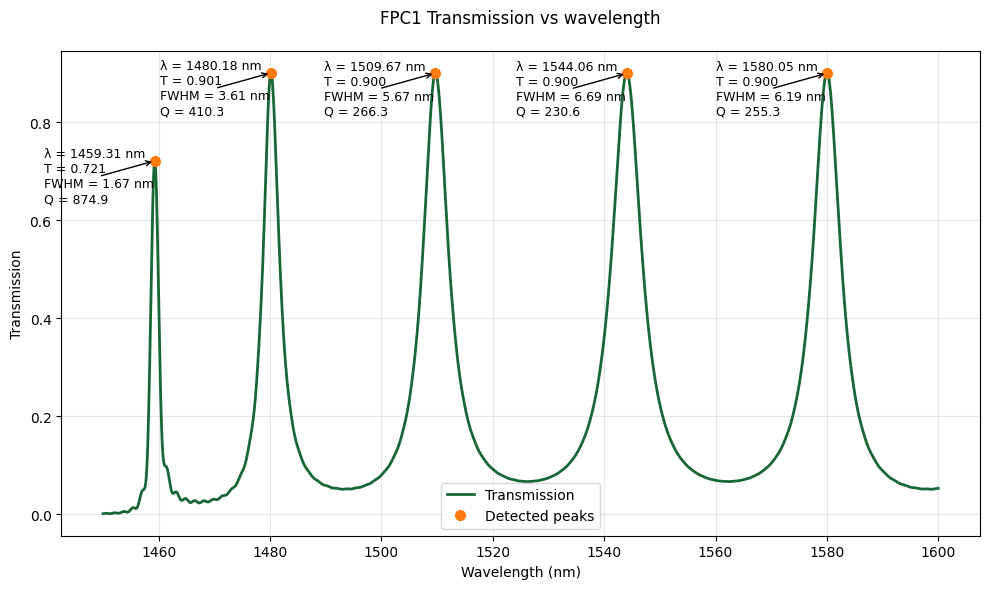


Transmission Peak Analysis
----------------------------------------------------------------------
Peak    Wavelength (nm)     Transmission      FWHM (nm)      Q           
----------------------------------------------------------------------
1       1459.309            0.7211            1.668          874.9       
2       1480.179            0.9007            3.607          410.3       
3       1509.672            0.9002            5.670          266.3       
4       1544.057            0.8998            6.695          230.6       
5       1580.045            0.9000            6.190          255.3       


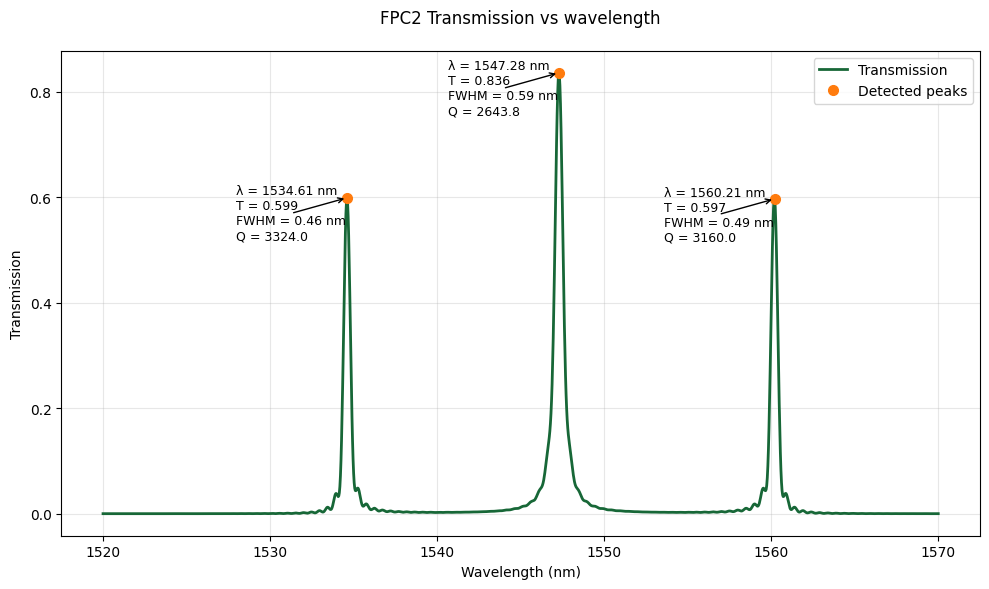


Transmission Peak Analysis
----------------------------------------------------------------------
Peak    Wavelength (nm)     Transmission      FWHM (nm)      Q           
----------------------------------------------------------------------
1       1534.606            0.5988            0.462          3324.0      
2       1547.285            0.8357            0.585          2643.8      
3       1560.208            0.5968            0.494          3160.0      


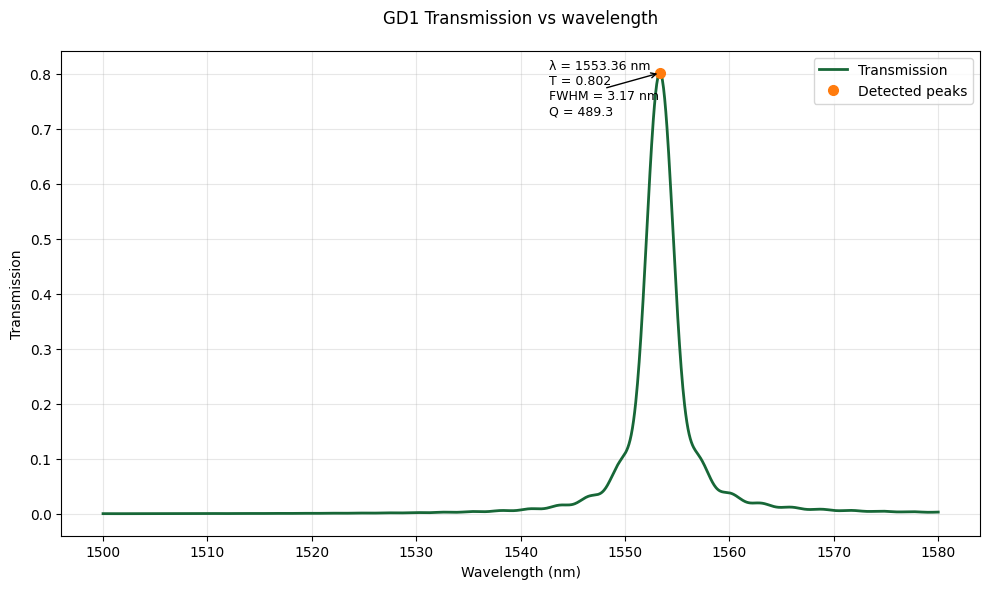


Transmission Peak Analysis
----------------------------------------------------------------------
Peak    Wavelength (nm)     Transmission      FWHM (nm)      Q           
----------------------------------------------------------------------
1       1553.361            0.8018            3.175          489.3       


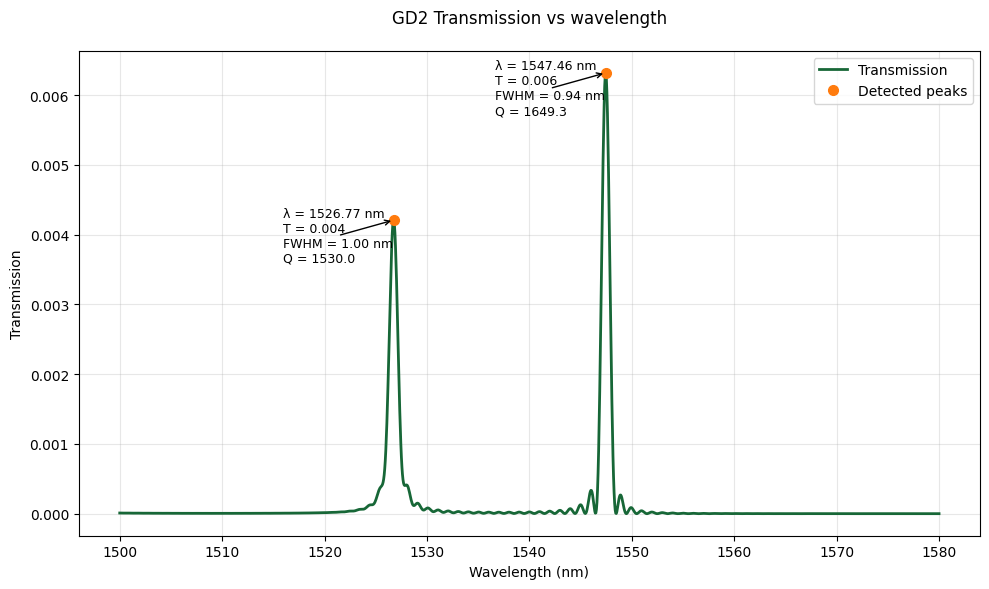


Transmission Peak Analysis
----------------------------------------------------------------------
Peak    Wavelength (nm)     Transmission      FWHM (nm)      Q           
----------------------------------------------------------------------
1       1526.765            0.0042            0.998          1530.0      
2       1547.461            0.0063            0.938          1649.3      
Selected GD2 peak: 1547.461 nm


In [64]:
# Getting transmission plots and dictionaries, and printing results for each device

results_FPC1 = plot_transmission_vs_wavelength(
    sim_TransmissionData_FPC1,
    title="FPC1 Transmission vs wavelength",
    prominence=0.01,
    peak_annotations_offset=(-80, -30)
)

print_peak_results(results_FPC1)


results_FPC2 = plot_transmission_vs_wavelength(
    sim_TransmissionData_FPC2,
    title="FPC2 Transmission vs wavelength",
    prominence=0.01,
    peak_annotations_offset=(-80, -30)
)

print_peak_results(results_FPC2)

results_GD1 = plot_transmission_vs_wavelength(
    sim_TransmissionData_GD1,
    title="GD1 Transmission vs wavelength",
    prominence=0.01,
    peak_annotations_offset=(-80, -30)
)

print_peak_results(results_GD1)


results_GD2 = plot_transmission_vs_wavelength(
    sim_TransmissionData_GD2,
    title="GD2 Transmission vs wavelength",
    prominence=0.001,
    peak_annotations_offset=(-80, -30)
)

print_peak_results(results_GD2)

requested_wavelength_GD2 = nearest_transmission_peak_nm(
    results_GD2,
    target_nm=1550.0
)

print(f"Selected GD2 peak: {requested_wavelength_GD2:.3f} nm")

In [65]:
# Select the detected FDTD transmission peak closest to 1550 nm.
# Use these SAME values in the field plots, angular sweeps, phase sweeps,
# and compression-factor calculations below.
target_peak_nm = 1550.0
requested_wavelength_FPC1 = nearest_transmission_peak_nm(results_FPC1, target_peak_nm)
requested_wavelength_FPC2 = nearest_transmission_peak_nm(results_FPC2, target_peak_nm)
requested_wavelength_GD1 = nearest_transmission_peak_nm(results_GD1, target_peak_nm)
requested_wavelength_GD2 = nearest_transmission_peak_nm(results_GD2, target_peak_nm)

print(f"FPC1: selected transmission peak = {requested_wavelength_FPC1:.3f} nm")
print(f"FPC2: selected transmission peak = {requested_wavelength_FPC2:.3f} nm")
print(f"GD1: selected transmission peak = {requested_wavelength_GD1:.3f} nm")
print(f"GD2: selected transmission peak = {requested_wavelength_GD2:.3f} nm")


FPC1: selected transmission peak = 1544.057 nm
FPC2: selected transmission peak = 1547.285 nm
GD1: selected transmission peak = 1553.361 nm
GD2: selected transmission peak = 1547.461 nm


### 10.3 - Field distribution and intensity evolution

**Note:** The field simulation results are retrieved from Tidy3D Cloud after the simulations have been executed through the Tidy3D web interface.

The field simulations are used to visualize the spatial evolution of the
electric field through each multilayer spaceplate.
Unlike the flux monitor, which integrates the electromagnetic power flux across a plane, the field monitor records the spatial distribution of the complex electric-field components in the $x$-$y$ plane.

To visualize the spatial distribution of the electric field and identify regions of field enhancement, we calculate the squared electric-field magnitude as

\[
|\mathbf E|^2=
|E_x|^2+|E_y|^2+|E_z|^2.
\]

The corresponding field intensity is proportional to

$$
|E|^2 =
|E_x|^2 + |E_y|^2 + |E_z|^2.
$$

The resulting field maps reveal the spatial distribution of the electric field, including regions of field enhancement arising from interference and resonant confinement within the multilayer structure.

The maximum transverse field intensity is also calculated at each
longitudinal position:

$$
I_{\mathrm{peak}}(x)
=
\max_y |E(x,y)|^2.
$$

This provides a measure of the longitudinal evolution of the field
intensity.

The physical beginning and end of the spaceplate are also identified
so that field behaviour inside the device can be distinguished from
behaviour after the device.

**Wavelength selection:** The analysis automatically chooses the detected
transmission resonance closest to **1550 nm** for each FPC device. The field
monitor may use a different spectral grid, so field plots use the closest
available monitored wavelength. Angular/phase sweeps and compression use the
selected transmission-peak wavelength itself (converted from nm to µm).


In [67]:
FPC1_field = "fdve-df472df9-1284-4f84-b60f-f86c18c8afa7"
FPC2_field = "fdve-96af6b48-96b3-449f-a6a3-24eebbb3a5a2"
GD1_field = "fdve-df2e2e6f-99ab-4173-8ab9-1b6d9601c77b"
GD2_field = "fdve-583f9c14-89c6-4c5a-b667-967ca67cae8a"

In [68]:
# Load field simulation results

sim_FieldData_FPC1 = web.load(FPC1_field)
sim_FieldData_FPC2 = web.load(FPC2_field)
sim_FieldData_GD1 = web.load(GD1_field)
sim_FieldData_GD2 = web.load(GD2_field)

Output()

23:20:54 UTC Loading results from simulation_data.hdf5

Output()

23:21:29 UTC Loading results from simulation_data.hdf5

Output()

23:21:50 UTC Loading results from simulation_data.hdf5

Output()

23:22:10 UTC Loading results from simulation_data.hdf5

#### FPC1

In [69]:
# Select the FPC1 field-monitor sample closest to its selected transmission peak
field_index_FPC1, actual_wavelength_FPC1 = (
    find_closest_wavelength_index(
        sim_FieldData_FPC1,
        requested_wavelength_FPC1
    )
)

print(
    f"Requested wavelength: "
    f"{requested_wavelength_FPC1:.3f} nm"
)
print(
    f"Closest available wavelength: "
    f"{actual_wavelength_FPC1:.3f} nm"
)
print(
    f"Wavelength difference: "
    f"{abs(actual_wavelength_FPC1 - requested_wavelength_FPC1):.3f} nm"
)
print(
    f"Field-monitor index: "
    f"{field_index_FPC1}"
)


Requested wavelength: 1544.057 nm
Closest available wavelength: 1543.548 nm
Wavelength difference: 0.509 nm
Field-monitor index: 35


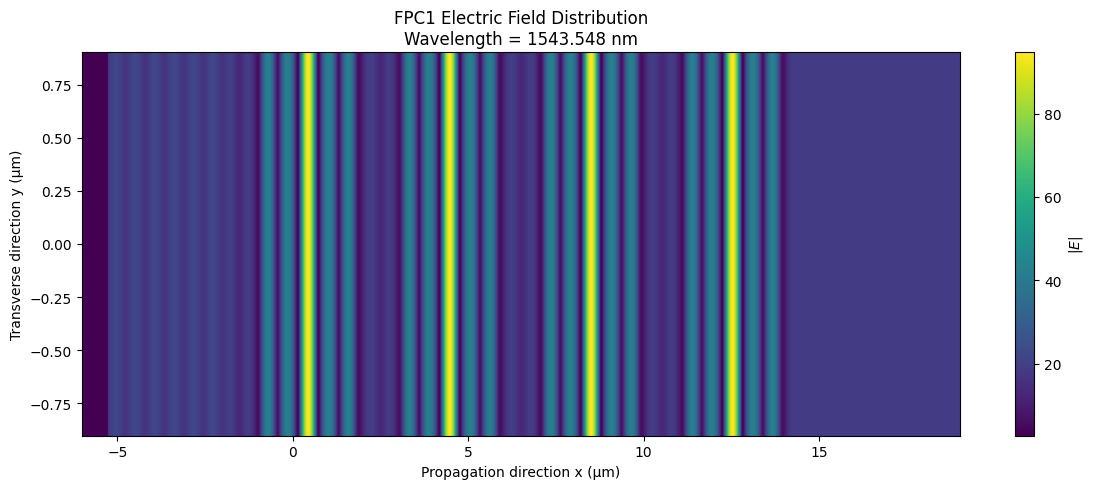

In [ ]:
# Plot FPC1 2D field distribution at/near its design wavelength

field_results_FPC1 = plot_field(
    sim_FieldData_FPC1,
    wavelength_index=field_index_FPC1,
    title="FPC1 Electric Field Distribution"
)

In [ ]:
# Getting the physical extent of the FPC1 spaceplate along the propagation direction x

x_start_FPC1, x_end_FPC1 = (
    get_spaceplate_extent(
        spaceplate_FPC1
    )
)
print(
    f"FPC1 extends from "
    f"x = {x_start_FPC1:.3f} µm "
    f"to x = {x_end_FPC1:.3f} µm"
)

FPC1 extends from x = -0.268 µm to x = 12.382 µm


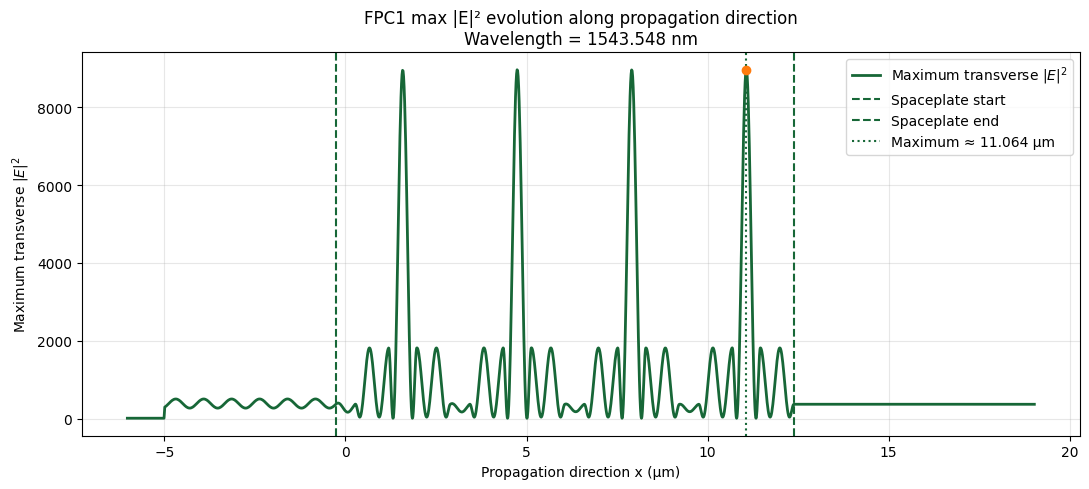

Maximum transverse field intensity occurs at x = 11.064 µm
Maximum |E|² = 8972.62


In [ ]:
# Plot the FPC1 evolution of the peak transverse |E|² along the propagation direction x

peak_evolution_FPC1 = (
    plot_peak_intensity_evolution(
        sim_FieldData_FPC1,
        wavelength_index=field_index_FPC1,
        spaceplate_extent=(
            x_start_FPC1,
            x_end_FPC1
        ),
        title="FPC1 max |E|² evolution along propagation direction"
    )
)

####FPC2

In [70]:
# Select the FPC2 field-monitor sample closest to its selected transmission peak

field_index_FPC2, actual_wavelength_FPC2 = (
    find_closest_wavelength_index(
        sim_FieldData_FPC2,
        requested_wavelength_FPC2
    )
)

print(
    f"Requested wavelength: "
    f"{requested_wavelength_FPC2:.3f} nm"
)
print(
    f"Closest available wavelength: "
    f"{actual_wavelength_FPC2:.3f} nm"
)
print(
    f"Wavelength difference: "
    f"{abs(actual_wavelength_FPC2 - requested_wavelength_FPC2):.3f} nm"
)
print(
    f"Field-monitor index: "
    f"{field_index_FPC2}"
)


Requested wavelength: 1547.285 nm
Closest available wavelength: 1547.378 nm
Wavelength difference: 0.093 nm
Field-monitor index: 44


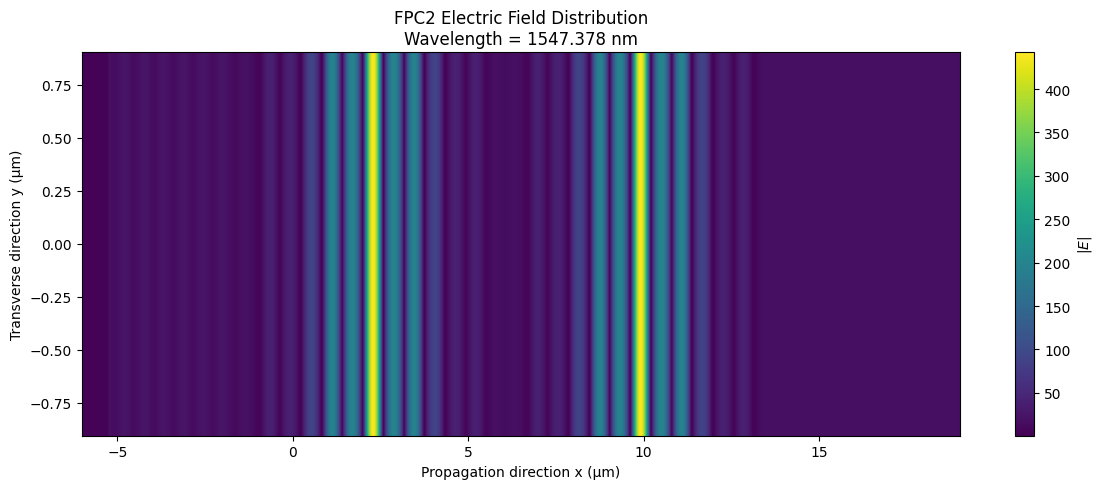

In [ ]:
# Plot FPC2 2D field distribution at/near its design wavelength

field_results_FPC2 = plot_field(
    sim_FieldData_FPC2,
    wavelength_index=field_index_FPC2,
    title="FPC2 Electric Field Distribution"
)

In [ ]:
# Getting the physical extent of the FPC2 spaceplate along the propagation direction x

x_start_FPC2, x_end_FPC2 = (
    get_spaceplate_extent(
        spaceplate_FPC2
    )
)
print(
    f"FPC2 extends from "
    f"x = {x_start_FPC2:.3f} µm "
    f"to x = {x_end_FPC2:.3f} µm"
)

FPC2 extends from x = -0.269 µm to x = 11.333 µm


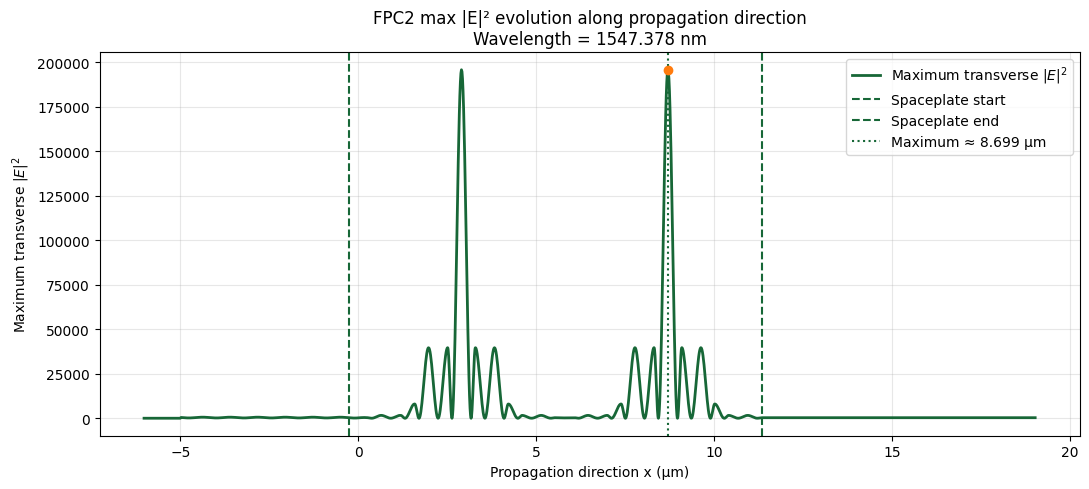

Maximum transverse field intensity occurs at x = 8.699 µm
Maximum |E|² = 195847


In [ ]:
# Plot the FPC2 evolution of the peak transverse |E|² along the propagation direction x

peak_evolution_FPC2 = (
    plot_peak_intensity_evolution(
        sim_FieldData_FPC2,
        wavelength_index=field_index_FPC2,
        spaceplate_extent=(
            x_start_FPC2,
            x_end_FPC2
        ),
        title="FPC2 max |E|² evolution along propagation direction"
    )
)

### 10.4 - Transmission vs Angle (Angular sweep)

**Note:** This part and onwards are done using OPTION 2 of the uploading options (Uploading and running the files on the Tidy3D web workspace )

We are calculating compression factor for the device FPC2 in [Ref. 1](#References).

In [79]:
# Use FPC1's detected transmission peak nearest 1550 nm.
# The angular-sweep builder expects wavelengths in microns.
FPC2_desired_wavelength = requested_wavelength_FPC2 * 1e-3

# Incident angles from 0° to 4° in steps of 0.5°
angles_FPC2 = np.arange(
    0,
    4.0 + 0.5,
    0.5
)
print("Incident angles:")
print(angles_FPC2)

# Build FPC1 simulations for each incident angle at the desired wavelength, and store
# them in a dictionary.
angle_sims_FPC2 = run_desired_wavelength_angle_sweep(
    structures=spaceplate_FPC2,
    desired_wavelength= FPC2_desired_wavelength,
    angles=angles_FPC2,
    run_time=8e-12,
    grid_steps=70,
    sim_size=(25, 2, 0),
    source_center=(-5, 0, 0),
    monitor_center=(18, 0, 0),
    monitor_size=(0, 1.8, 1.8),
    sim_center=(6.5, 0, 0),
)


Incident angles:
[0.  0.5 1.  1.5 2.  2.5 3.  3.5 4. ]
Building simulation for λ = 1547.28 nm, angle = +0.0°
Building simulation for λ = 1547.28 nm, angle = +0.5°
Building simulation for λ = 1547.28 nm, angle = +1.0°
Building simulation for λ = 1547.28 nm, angle = +1.5°
Building simulation for λ = 1547.28 nm, angle = +2.0°
Building simulation for λ = 1547.28 nm, angle = +2.5°
Building simulation for λ = 1547.28 nm, angle = +3.0°
Building simulation for λ = 1547.28 nm, angle = +3.5°
Building simulation for λ = 1547.28 nm, angle = +4.0°


In [80]:
# Run the FPC1 angular-sweep simulations.
# web.run() returns the simulation results directly,
# so there is no need to call web.load() afterward.

angle_data_FPC2 = {}

for angle, sim in angle_sims_FPC2.items():

    print(
        f"Running FPC1 at "
        f"λ = {FPC2_desired_wavelength * 1e3:.2f} nm, "
        f"angle = {angle:+.1f}°"
    )

    angle_data_FPC2[angle] = web.run(
        sim,
        task_name=f"FPC2_Angle_{angle:+.1f}deg"
    )

Running FPC1 at λ = 1547.28 nm, angle = +0.0°


23:34:11 UTC Created task 'FPC2_Angle_+0.0deg' with resource_id                 
             'fdve-2ab71c01-b4c8-4d06-b793-073438178242' and task_type 'FDTD'.

             View task using web UI at                                          
             ]8;id=323360;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2ab71c01-b4c8-4d06-b793-073438178242\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=967675;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2ab71c01-b4c8-4d06-b793-073438178242\taskId]8;;\]8;id=323360;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2ab71c01-b4c8-4d06-b793-073438178242\=]8;;\]8;id=417743;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2ab71c01-b4c8-4d06-b793-073438178242\fdve]8;;\]8;id=323360;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2ab71c01-b4c8-4d06-b793-073438178242\-2ab71c01-b4c]8;;\
             ]8;id=323360;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2ab71c01-b4c8-4d06-b793-073438178242\8-4d06-b793-073438178242']8;;\.

             Task folder: ]8;id=691324;https://tidy3d.simulation.cloud/folders/folder-7b542f08-3da8-461c-9d93-ae083474555e\'default']8;;\.

Output()

23:34:14 UTC Estimated FlexCredit cost: 0.070. This assumes the FDTD solver runs
             for the full simulation time; if early shutoff is reached, the     
             billed cost can be lower. Use 'web.real_cost(task_id)' to get the  
             billed FlexCredit cost after a simulation run.

... (151 outputs left out)

             View simulation result at                                          
             ]8;id=995576;https://tidy3d.simulation.cloud/workbench?taskId=fdve-169607fb-d940-4041-ab2c-e768528588e2\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=853785;https://tidy3d.simulation.cloud/workbench?taskId=fdve-169607fb-d940-4041-ab2c-e768528588e2\taskId]8;;\]8;id=995576;https://tidy3d.simulation.cloud/workbench?taskId=fdve-169607fb-d940-4041-ab2c-e768528588e2\=]8;;\]8;id=171787;https://tidy3d.simulation.cloud/workbench?taskId=fdve-169607fb-d940-4041-ab2c-e768528588e2\fdve]8;;\]8;id=995576;https://tidy3d.simulation.cloud/workbench?taskId=fdve-169607fb-d940-4041-ab2c-e768528588e2\-169607fb-d94]8;;\
             ]8;id=995576;https://tidy3d.simulation.cloud/workbench?taskId=fdve-169607fb-d940-4041-ab2c-e768528588e2\0-4041-ab2c-e768528588e2']8;;\.

Output()

00:06:14 UTC Loading results from simulation_data.hdf5

             WARNING: Simulation final field decay value of 0.0076 is greater   
             than the simulation shutoff threshold of 1e-05. Consider running   
             the simulation again with a larger 'run_time' duration for more    
             accurate results.                                                  

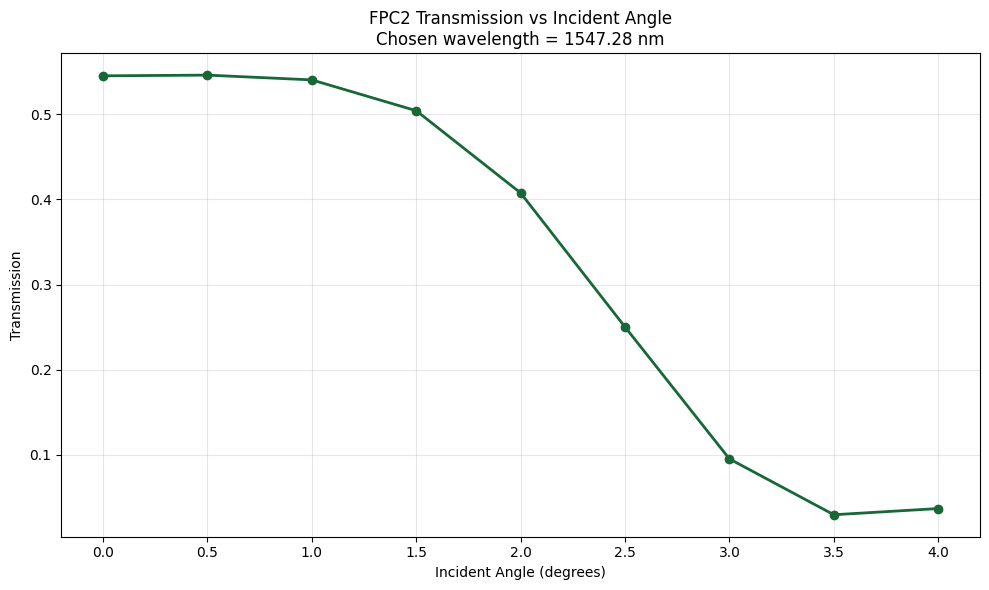


FPC2 Transmission at 1547.28 nm
--------------------------------------------------
Angle =  0.0°   Transmission = 0.544981
Angle =  0.5°   Transmission = 0.545827
Angle =  1.0°   Transmission = 0.540213
Angle =  1.5°   Transmission = 0.504038
Angle =  2.0°   Transmission = 0.407486
Angle =  2.5°   Transmission = 0.250184
Angle =  3.0°   Transmission = 0.095312
Angle =  3.5°   Transmission = 0.029806
Angle =  4.0°   Transmission = 0.037071


In [81]:
# Plot transmission vs angle for FPC1 and print results

angle_results_FPC2 = plot_transmission_vs_angle(
    angle_data_FPC2,
        desired_wavelength=FPC2_desired_wavelength,
        title="FPC2 Transmission vs Incident Angle"
)

# ---------------------------------------------------------
# Print numerical results
# ---------------------------------------------------------
print(
    f"\nFPC2 Transmission at "
    f"{FPC2_desired_wavelength * 1e3:.2f} nm"
)

print("-" * 50)
for angle, transmission in zip(
    angle_results_FPC2["angle_deg"],
    angle_results_FPC2["transmission"]
):
    print(
        f"Angle = {angle:4.1f}°   "
        f"Transmission = {transmission:.6f}"
    )


## 10.5 — Compression

The spaceplate compression factor is determined from the angular dependence of the transmission phase obtained from the FDTD simulations. The following analysis is based on the spaceplate characterization method described in Supplementary Method 1 of [Ref. 1](#References).

At a fixed wavelength, two simulations are performed for each angle of incidence: one containing the multilayer spaceplate and one containing only the background medium. The transmitted electric field is projected onto the p-polarization direction, and the transverse phase dependence of the plane wave is removed before integrating the complex field across the monitor.

The complex transmission coefficient is then obtained by dividing the device field by the corresponding empty-space reference field:

$$
t(\theta) =
\frac{E_{\mathrm{device}}(\theta)}
{E_{\mathrm{reference}}(\theta)}.
$$

This normalization removes the common phase contributions associated with the source, monitor positions, and propagation through the background medium. The resulting transmission coefficient describes the optical response of the spaceplate relative to propagation through an equivalent region of the background medium.

The transmission phase is obtained from the complex transmission coefficient:

$$
\phi(\theta) =
\operatorname{unwrap}
\left[\arg\left(t(\theta)\right)\right].
$$

The phase is subsequently referenced to its normal-incidence value:

$$
\phi_{\mathrm{relative}}(\theta)
=
\phi(\theta)-\phi(0).
$$

Since the transmission coefficient is normalized to an empty-space reference, the phase contribution associated with propagation through the background medium over the physical thickness of the device must be added back to recover the transmission phase convention used in [Ref. 1](#References):

$$
\phi_t(\theta)
=
\phi_{\mathrm{relative}}(\theta)
+
k_0d\left[\cos(\theta)-1\right],
$$

where $d$ is the physical thickness of the spaceplate and

$$
k_0 =
\frac{2\pi n_{\mathrm{bg}}}{\lambda}
$$

is the wavenumber in the background medium, with $\lambda$ denoting the vacuum wavelength.

Rather than numerically differentiating the FDTD phase data directly, the reconstructed transmission phase is first fitted over the selected angular range to the angular phase response of an ideal spaceplate:

$$
\phi_{\mathrm{fit}}(\theta)
=
A\left[\cos(\theta)-1\right],
$$

where

$$
A=k_0Rd.
$$

This fitting procedure reduces the sensitivity of the phase derivative to numerical noise. The angular phase derivative is then obtained analytically from the fitted phase:

$$
\frac{d\phi_{\mathrm{fit}}}{d\theta}
=
-A\sin(\theta).
$$

The lateral displacement along the exit interface of the spaceplate is calculated as

$$
w(\theta)
=
-\frac{1}{k_0\cos(\theta)}
\frac{d\phi_{\mathrm{fit}}}{d\theta}.
$$

The geometrical lateral displacement associated with propagation through the background medium over the physical thickness $d$ is

$$
w_a(\theta)
=
d\tan(\theta).
$$

Following the experimental characterization described in [Ref. 1](#References), the transverse displacement is obtained by projecting the difference between these displacements onto the direction perpendicular to the incident beam. Using the experimental sign convention,

$$
\Delta x(\theta)
=
\left[w_a(\theta)-w(\theta)\right]
\cos(\theta).
$$

For an ideal spaceplate, the resulting transverse displacement is

$$
\Delta x(\theta)
=
-(R-1)d\sin(\theta).
$$

The calculation searches for the longest contiguous angular interval over which the reconstructed transverse displacement is approximately linear. This interval is used to extract the compression factor following the linear displacement relation employed in the experimental characterization.

Since the displacement is reconstructed from the fitted phase, the selected interval characterizes the linearity of the fitted response. The validity of the ideal spaceplate approximation must also be assessed by comparing the original FDTD phase with the fitted phase.

In the paraxial regime, where $\sin(\theta)\approx\theta$,

$$
\Delta x
\approx
-(R-1)d\theta.
$$

Therefore, if the linear fit is

$$
\Delta x
=
m\theta+b,
$$

the compression factor is

$$
R
=
1-\frac{m}{d},
$$

where the angle $\theta$ is expressed in radians.

The compression factor obtained from the $\Delta x$ linear fit is used as the primary FDTD compression-factor result, following the experimental characterization method described in [Ref. 1](#References).

The corresponding ideal spaceplate phase is then constructed as

$$
\phi_{\mathrm{ideal}}(\theta)
=
\frac{2\pi n_{\mathrm{bg}}}{\lambda}
Rd
\left[\cos(\theta)-1\right].
$$

The reconstructed FDTD device phase, $\phi_t(\theta)$, is compared with this ideal phase to evaluate how closely the simulated device follows the expected spaceplate response.

An additional compression-factor estimate is obtained directly from the cosine phase fit. Since

$$
A=k_0Rd,
$$

the compression factor obtained from the phase fit is

$$
R_{\mathrm{phase}}
=
\frac{A}{k_0d}.
$$

This provides a consistency check between the phase-based and displacement-based calculations of the compression factor. Since both estimates originate from the same fitted transmission phase, they are not independent.

The effective propagation distance is

$$
d_{\mathrm{eff}}
=
Rd.
$$

Assuming that the physical thickness of the device is known exactly, the nominal fitting uncertainty in the compression factor is obtained from the uncertainty in the fitted $\Delta x$ slope:

$$
\sigma_R
=
\frac{\sigma_m}{d}.
$$

This quantity characterizes the uncertainty associated with the linear displacement fit. It does not account for the uncertainty propagated from the cosine phase fit or systematic numerical errors associated with spatial discretization, simulation time, angular sampling, and the selected fitting interval.


In [88]:
# ============================================================
# DEVICE THICKNESS
# ============================================================


# Calculate thickness for all devices

d_FPC1 = get_device_thickness(
    spaceplate_FPC1
)

d_FPC2 = get_device_thickness(
    spaceplate_FPC2
)

d_GD1 = get_device_thickness(
    spaceplate_GD1
)

d_GD2 = get_device_thickness(
    spaceplate_GD2
)


print(
    f"FPC1 thickness = {d_FPC1:.6f} µm"
)

print(
    f"FPC2 thickness = {d_FPC2:.6f} µm"
)

print(
    f"GD1 thickness  = {d_GD1:.6f} µm"
)

print(
    f"GD2 thickness  = {d_GD2:.6f} µm"
)

FPC1 thickness = 12.649600 µm
FPC2 thickness = 11.601627 µm
GD1 thickness  = 2.483300 µm
GD2 thickness  = 13.418600 µm


In [83]:
# ============================================================
# FPC1 PHASE SWEEP
# ============================================================

angles_compression_FPC2 = np.arange(
    0.0,
    3.5 + 0.1,
    0.1
)

compression_data_FPC2 = run_phase_angle_sweep(
    structures=spaceplate_FPC2,
    wavelength=requested_wavelength_FPC2 * 1e-3,  # selected peak, µm
    angles=angles_compression_FPC2,
    run_time=8e-12,
    grid_steps=70,
    sim_size=(25, 2, 0),
    source_center=(-5, 0, 0),
    monitor_x=18,
    monitor_y_span=1.8,
    sim_center=(6.5, 0, 0),
)


Running phase simulation: lambda = 1547.285 nm, angle = +0.00 deg


00:06:16 UTC Created task 'Phase_Device_+0.00deg' with resource_id              
             'fdve-537f1fea-7d03-4666-8f71-6904932d9b5a' and task_type 'FDTD'.

             View task using web UI at                                          
             ]8;id=298845;https://tidy3d.simulation.cloud/workbench?taskId=fdve-537f1fea-7d03-4666-8f71-6904932d9b5a\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=854933;https://tidy3d.simulation.cloud/workbench?taskId=fdve-537f1fea-7d03-4666-8f71-6904932d9b5a\taskId]8;;\]8;id=298845;https://tidy3d.simulation.cloud/workbench?taskId=fdve-537f1fea-7d03-4666-8f71-6904932d9b5a\=]8;;\]8;id=147292;https://tidy3d.simulation.cloud/workbench?taskId=fdve-537f1fea-7d03-4666-8f71-6904932d9b5a\fdve]8;;\]8;id=298845;https://tidy3d.simulation.cloud/workbench?taskId=fdve-537f1fea-7d03-4666-8f71-6904932d9b5a\-537f1fea-7d0]8;;\
             ]8;id=298845;https://tidy3d.simulation.cloud/workbench?taskId=fdve-537f1fea-7d03-4666-8f71-6904932d9b5a\3-4666-8f71-6904932d9b5a']8;;\.

             Task folder: ]8;id=472012;https://tidy3d.simulation.cloud/folders/folder-7b542f08-3da8-461c-9d93-ae083474555e\'default']8;;\.

Output()

00:06:18 UTC Estimated FlexCredit cost: 0.070. This assumes the FDTD solver runs
             for the full simulation time; if early shutoff is reached, the     
             billed cost can be lower. Use 'web.real_cost(task_id)' to get the  
             billed FlexCredit cost after a simulation run.

... (1,219 outputs left out)

02:24:59 UTC status = success

             View simulation result at                                          
             ]8;id=967262;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a5bef616-b37c-4183-a1f3-64d889fb44b4\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=963025;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a5bef616-b37c-4183-a1f3-64d889fb44b4\taskId]8;;\]8;id=967262;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a5bef616-b37c-4183-a1f3-64d889fb44b4\=]8;;\]8;id=672104;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a5bef616-b37c-4183-a1f3-64d889fb44b4\fdve]8;;\]8;id=967262;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a5bef616-b37c-4183-a1f3-64d889fb44b4\-a5bef616-b37]8;;\
             ]8;id=967262;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a5bef616-b37c-4183-a1f3-64d889fb44b4\c-4183-a1f3-64d889fb44b4']8;;\.

Output()

02:25:01 UTC Loading results from simulation_data.hdf5


FPC2 FDTD Compression Factor Calculation
Wavelength              = 1547.285 nm
Device thickness        = 11.601627 µm
Phase fit range         = 0.000° to 1.500°
Phase model             = A [cos(theta) - 1]
Phase coefficient A     = 1290.47430939
Physical phase fit R²   = 0.998969

Compression from phase  = 27.391814
Effective distance      = 317.789605 µm

Delta-x search range    = 0.000° to 3.500°
Delta-x linear range    = 0.000° to 1.500°
Delta-x slope           = -306.15583197 µm/rad
Delta-x intercept       = -0.00017662 µm
Delta-x fit R²          = 1.000000

Compression from Δx     = 27.389043 ± 0.000335
Effective distance Δx   = 317.757459 ± 0.003891 µm

FDTD phase polynomial   = degree 3
FDTD phase-data fit R²  = 0.999941
Phase RMS residual      = 4.624761e-03 rad


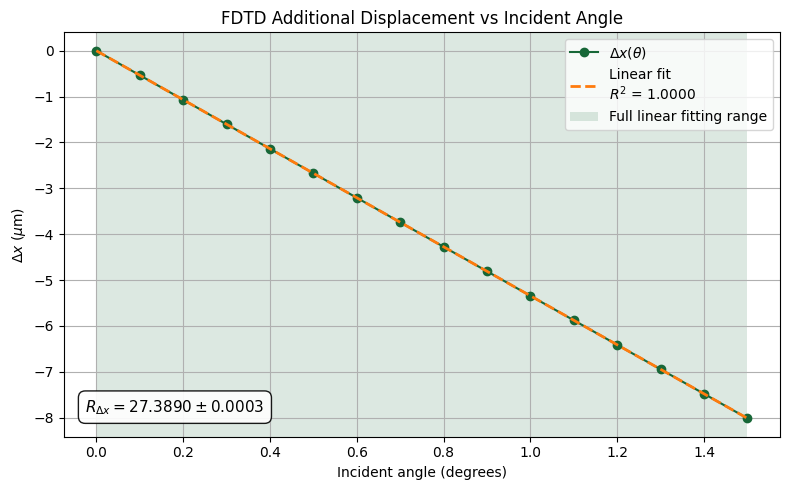

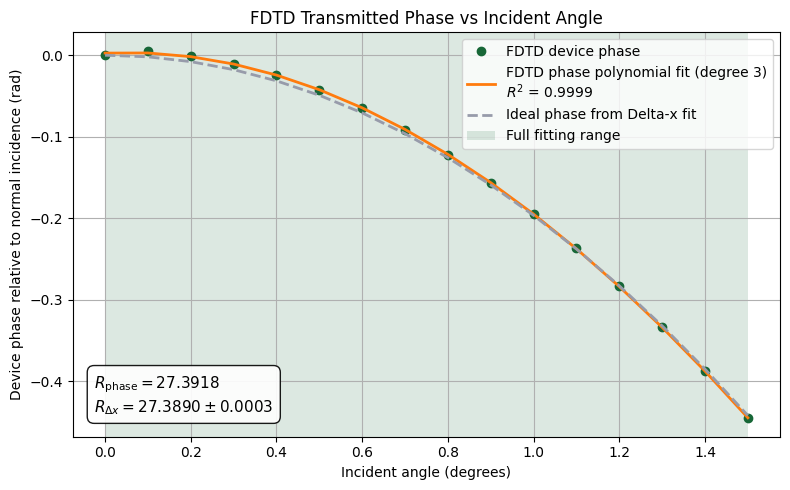


FPC2 FDTD compression data:
---------------------------------------------------------------------------------------------------------
   Angle    Device phase     dphi/dtheta               w             w_a         Delta x
---------------------------------------------------------------------------------------------------------
    0.00      0.00000000     -0.00000000      0.00000000      0.00000000      0.00000000
    0.10      0.00554076     -2.25230142      0.55464806      0.02024868     -0.53439856
    0.20     -0.00043254     -4.50459597      1.10929949      0.04049748     -1.06879550
    0.30     -0.01042703     -6.75687681      1.66395769      0.06074653     -1.60318918
    0.40     -0.02486795     -9.00913706      2.21862602      0.08099595     -2.13757798
    0.50     -0.04294134    -11.26136987      2.77330787      0.10124586     -2.67196026
    0.60     -0.06530543    -13.51356838      3.32800662      0.12149640     -3.20633441
    0.70     -0.09170605    -15.76572572      3

In [92]:
# ============================================================
# FPC2 FDTD COMPRESSION FACTOR
# ============================================================

compression_FPC2 = compute_fdtd_compression_factor(
    phase_data=compression_data_FPC2["phase_relative_rad"],
    angles_deg=compression_data_FPC2["angles_deg"],
    wavelength=requested_wavelength_FPC2* 1e-3,
    device_thickness=d_FPC2,
    n_bg=1.0,
    exclude_angles=None,
    plot=True,
    title="FPC2 FDTD Compression Factor Calculation",
)

print("\nFPC2 FDTD compression data:")
print("-" * 105)
print(
    f"{'Angle':>8} "
    f"{'Device phase':>15} "
    f"{'dphi/dtheta':>15} "
    f"{'w':>15} "
    f"{'w_a':>15} "
    f"{'Delta x':>15}"
)
print("-" * 105)

for angle, phase, derivative, w, wa, dx in zip(
    compression_FPC2["angles_deg"],
    compression_FPC2["phase_device_rad"],
    compression_FPC2["dphi_dtheta"],
    compression_FPC2["w"],
    compression_FPC2["w_a"],
    compression_FPC2["delta_x"],
):
    print(
        f"{angle:8.2f} "
        f"{phase:15.8f} "
        f"{derivative:15.8f} "
        f"{w:15.8f} "
        f"{wa:15.8f} "
        f"{dx:15.8f}"
    )

Note on the simulation results:
The resulting compression factor is lower than experimentally measured compression fctor for FPC2 in [Ref. 1](#References) of 41.9. This discrepancy is caused by the limitation of the grid step.

While higher grid step value will bring the result of this simulation closer to the experimental  values, it will also increase the simmulation cost.

## References

1. R. Hogan, Y. Mamchur, R. M. Córdova-Castro, G. Carlow, B. T. Sullivan,
   O. Reshef, R. W. Boyd, and J. S. Lundeen,
   **Experimental demonstration of high space compression by optical spaceplates**,
   *Nature Communications* **17** (2026).
   DOI: https://doi.org/10.1038/s41467-026-71500-1